<a href="https://colab.research.google.com/github/edu-moraess/Commodity-Intelligence-Terminal/blob/main/Vyra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:


# ============================================================
# VYRA CORE | AUTHENTICATED BRANCH ZIP DOWNLOAD
# ArqTech Labs
# ============================================================

import os
import io
import zipfile
import requests
from pathlib import Path
from getpass import getpass
from google.colab import files

OWNER = "edu-moraess"
REPO = "vyra-core"
BRANCH = "feat/core-contract-foundation"

DOWNLOAD_DIR = Path("/content/Downloads")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DOWNLOAD_DIR / "vyra-core-feat-core-contract-foundation.zip"

print("=" * 65)
print("VYRA CORE | BRANCH DOWNLOAD")
print("=" * 65)

# 1. Autenticação
print("\n[1/5] Autenticação GitHub")
print("Se o repositório for privado, informe um token")
print("com permissão Contents: Read Only.")
print("Se for público, basta pressionar Enter.")

TOKEN = getpass("GitHub token (não será exibido): ").strip()

HEADERS = {
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28"
}

if TOKEN:
    HEADERS["Authorization"] = f"Bearer {TOKEN}"

# 2. Verificar branch e obter SHA
print("\n[2/5] Verificando branch...")

API_URL = (
    f"https://api.github.com/repos/"
    f"{OWNER}/{REPO}/branches/{BRANCH}"
)

response = requests.get(
    API_URL,
    headers=HEADERS,
    timeout=30
)

if response.status_code == 404:
    raise RuntimeError(
        "Branch não encontrada ou repositório inacessível. "
        "Verifique o token e as permissões."
    )

response.raise_for_status()

branch_data = response.json()
COMMIT_SHA = branch_data["commit"]["sha"]

print("Branch:", BRANCH)
print("Commit:", COMMIT_SHA)

# 3. Baixar ZIP da branch
print("\n[3/5] Baixando ZIP do GitHub...")

ZIP_URL = (
    f"https://api.github.com/repos/"
    f"{OWNER}/{REPO}/zipball/{BRANCH}"
)

response = requests.get(
    ZIP_URL,
    headers=HEADERS,
    timeout=180
)

response.raise_for_status()

content = response.content

if not content.startswith(b"PK"):
    raise RuntimeError(
        "A resposta não parece ser um arquivo ZIP válido."
    )

# 4. Validar integridade e salvar
print("\n[4/5] Validando e salvando arquivo...")

with zipfile.ZipFile(io.BytesIO(content)) as archive:
    bad_file = archive.testzip()

    if bad_file:
        raise RuntimeError(
            f"Arquivo ZIP corrompido: {bad_file}"
        )

ZIP_PATH.write_bytes(content)

print("ZIP íntegro: SIM")
print("Tamanho: {:.2f} MB".format(len(content) / 1024**2))
print("Arquivo:", ZIP_PATH)
print("SHA do commit:", COMMIT_SHA)

# 5. Baixar para o dispositivo
print("\n[5/5] Enviando arquivo para download...")

assert ZIP_PATH.exists(), "ZIP não encontrado."

files.download(str(ZIP_PATH))

print("\n" + "=" * 65)
print("DOWNLOAD PREPARADO COM SUCESSO")
print("=" * 65)

VYRA CORE | BRANCH DOWNLOAD

[1/5] Autenticação GitHub
Se o repositório for privado, informe um token
com permissão Contents: Read Only.
Se for público, basta pressionar Enter.
GitHub token (não será exibido): ··········

[2/5] Verificando branch...
Branch: feat/core-contract-foundation
Commit: 510945ec8d5642de205646450373220ee9cf9f05

[3/5] Baixando ZIP do GitHub...

[4/5] Validando e salvando arquivo...
ZIP íntegro: SIM
Tamanho: 0.02 MB
Arquivo: /content/Downloads/vyra-core-feat-core-contract-foundation.zip
SHA do commit: 510945ec8d5642de205646450373220ee9cf9f05

[5/5] Enviando arquivo para download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DOWNLOAD PREPARADO COM SUCESSO


In [2]:


# ============================================================
# VYRA CORE | MANUAL VALIDATION
# Extração segura + instalação + testes
# ============================================================

import sys
import zipfile
import subprocess
from pathlib import Path

ZIP = Path(
    "/content/Downloads/"
    "vyra-core-feat-core-contract-foundation.zip"
)

COMMIT = "510945ec8d5642de205646450373220ee9cf9f05"

print("=" * 65)
print("VYRA CORE | VALIDATION")
print("=" * 65)

assert ZIP.is_file(), f"ZIP não encontrado: {ZIP}"

# 1. Validar conteúdo
print("\n[1/6] Inspecionando ZIP...")

with zipfile.ZipFile(ZIP) as z:
    bad = z.testzip()
    assert bad is None, f"ZIP corrompido: {bad}"

    names = z.namelist()
    assert names, "ZIP vazio"

    for name in names:
        p = Path(name)
        assert not p.is_absolute()
        assert ".." not in p.parts, f"Caminho inseguro: {name}"

print("Arquivos no ZIP:", len(names))

# 2. Extrair em diretório exclusivo
print("\n[2/6] Extração segura...")

DEST = Path(f"/content/vyra_core_validation_{COMMIT[:8]}")
assert not DEST.exists(), f"Diretório já existe: {DEST}"

DEST.mkdir(parents=True)

with zipfile.ZipFile(ZIP) as z:
    z.extractall(DEST)

# Localizar raiz do projeto
roots = list(DEST.rglob("pyproject.toml"))
assert len(roots) == 1, f"Esperado 1 pyproject.toml; encontrados: {len(roots)}"

REPO = roots[0].parent

print("Raiz:", REPO)

# 3. Conferir estrutura esperada
print("\n[3/6] Conferindo arquivos...")

required = [
    "pyproject.toml",
    "src/vyra_core/__init__.py",
    "src/vyra_core/contracts/temporal.py",
    "src/vyra_core/contracts/spatial.py",
    "src/vyra_core/contracts/provenance.py",
    "src/vyra_core/contracts/envelope.py",
    "tests/contracts/test_contracts.py",
    "tests/validation/test_compatibility.py",
]

missing = [f for f in required if not (REPO / f).is_file()]

for f in required:
    print(("OK   " if (REPO / f).is_file() else "FALTA ") + f)

assert not missing, f"Arquivos ausentes: {missing}"

# 4. Instalar em modo editável
print("\n[4/6] Instalando dependências de desenvolvimento...")

install = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", ".[dev]"],
    cwd=REPO,
    text=True
)

if install.returncode != 0:
    raise RuntimeError("Falha na instalação.")

# 5. Compilação
print("\n[5/6] Compileall...")

compile_result = subprocess.run(
    [sys.executable, "-m", "compileall", "-q", "src", "tests"],
    cwd=REPO
)

print("Compileall:", "PASS" if compile_result.returncode == 0 else "FAIL")
assert compile_result.returncode == 0

# 6. Testes
print("\n[6/6] Executando pytest...")

test_result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=REPO
)

print("\n" + "=" * 65)
print("RESULTADO FINAL")
print("=" * 65)
print("Commit:", COMMIT)
print("Estrutura: PASS")
print("Instalação: PASS")
print("Compileall: PASS" if compile_result.returncode == 0 else "Compileall: FAIL")
print("Pytest:", "PASS" if test_result.returncode == 0 else "FAIL")

if test_result.returncode != 0:
    print("\nVALIDAÇÃO REPROVADA — investigar falhas.")
else:
    print("\nVALIDAÇÃO APROVADA — testes concluídos.")

print("Diretório:", REPO)

VYRA CORE | VALIDATION

[1/6] Inspecionando ZIP...
Arquivos no ZIP: 32

[2/6] Extração segura...
Raiz: /content/vyra_core_validation_510945ec/edu-moraess-vyra-core-510945ec8d5642de205646450373220ee9cf9f05

[3/6] Conferindo arquivos...
OK   pyproject.toml
OK   src/vyra_core/__init__.py
OK   src/vyra_core/contracts/temporal.py
OK   src/vyra_core/contracts/spatial.py
OK   src/vyra_core/contracts/provenance.py
OK   src/vyra_core/contracts/envelope.py
OK   tests/contracts/test_contracts.py
OK   tests/validation/test_compatibility.py

[4/6] Instalando dependências de desenvolvimento...

[5/6] Compileall...
Compileall: PASS

[6/6] Executando pytest...

RESULTADO FINAL
Commit: 510945ec8d5642de205646450373220ee9cf9f05
Estrutura: PASS
Instalação: PASS
Compileall: PASS
Pytest: PASS

VALIDAÇÃO APROVADA — testes concluídos.
Diretório: /content/vyra_core_validation_510945ec/edu-moraess-vyra-core-510945ec8d5642de205646450373220ee9cf9f05


In [3]:


import os
import requests
import zipfile
from pathlib import Path

REPO = "edu-moraess/vyra-core"
BRANCH = "feat/core-contract-foundation"

token = os.environ.get("GITHUB_TOKEN")

if not token:
    from getpass import getpass
    token = getpass("GitHub Fine-grained token: ")

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json"
}

# 1. Consultar HEAD atual
url = f"https://api.github.com/repos/{REPO}/branches/{BRANCH}"
response = requests.get(url, headers=headers, timeout=30)
response.raise_for_status()

sha = response.json()["commit"]["sha"]
print("HEAD atual:", sha)

# 2. Baixar ZIP da branch
zip_url = f"https://api.github.com/repos/{REPO}/zipball/{BRANCH}"
response = requests.get(zip_url, headers=headers, timeout=60)
response.raise_for_status()

output = Path("/content/vyra_core_latest.zip")
output.write_bytes(response.content)

# 3. Verificar integridade
with zipfile.ZipFile(output, "r") as archive:
    bad_file = archive.testzip()
    assert bad_file is None, f"ZIP corrompido: {bad_file}"
    entries = archive.namelist()

print("ZIP:", output)
print("Tamanho:", round(output.stat().st_size / 1024, 2), "KB")
print("Entradas:", len(entries))
print("Integridade: PASS")

assert any(name.endswith("/pyproject.toml") for name in entries)
print("Estrutura básica: PASS")

# 4. Baixar para seu dispositivo
from google.colab import files
files.download(str(output))

GitHub Fine-grained token: ··········
HEAD atual: b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11
ZIP: /content/vyra_core_latest.zip
Tamanho: 26.19 KB
Entradas: 34
Integridade: PASS
Estrutura básica: PASS


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

import os
import sys
import shutil
import zipfile
import subprocess
import compileall
from pathlib import Path

ZIP = Path("/content/vyra_core_latest.zip")
DEST = Path("/content/vyra_core_validation")
EXPECTED_HEAD = "b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11"

print("=" * 65)
print("VYRA CORE | MANUAL VALIDATION")
print("=" * 65)

# 1. Extração limpa
if DEST.exists():
    shutil.rmtree(DEST)

DEST.mkdir(parents=True)

with zipfile.ZipFile(ZIP) as z:
    z.extractall(DEST)

projects = list(DEST.rglob("pyproject.toml"))
assert projects, "FAIL: pyproject.toml não encontrado"

PROJECT = projects[0].parent
os.chdir(PROJECT)

print("\n[1/6] Estrutura")
print("Project:", PROJECT)
print("PASS")

# 2. Instalação
print("\n[2/6] Instalação editável")
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", ".[dev]"],
    check=True
)
print("PASS")

# 3. Compilação
print("\n[3/6] Compileall")
compiled = compileall.compile_dir(
    str(PROJECT / "src"),
    quiet=1
)
assert compiled, "FAIL: erro de compilação"
print("PASS")

# 4. Testes
print("\n[4/6] Pytest")
result = subprocess.run(
    [sys.executable, "-m", "pytest", "-v"],
    text=True
)
assert result.returncode == 0, "FAIL: pytest"
print("PASS")

# 5. Importação
print("\n[5/6] Importação")
import vyra_core
print("Module:", vyra_core.__file__)
print("PASS")

# 6. Relatório
print("\n[6/6] Resultado")
print("Expected HEAD:", EXPECTED_HEAD)
print("ZIP size:", ZIP.stat().st_size)
print("Python:", sys.version)
print("Working directory:", os.getcwd())

print("\n" + "=" * 65)
print("VALIDATION COMPLETE")
print("=" * 65)

VYRA CORE | MANUAL VALIDATION

[1/6] Estrutura
Project: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11
PASS

[2/6] Instalação editável
PASS

[3/6] Compileall
PASS

[4/6] Pytest
PASS

[5/6] Importação


ModuleNotFoundError: No module named 'vyra_core'

In [5]:

import os
import sys
import importlib.util
import importlib.metadata as metadata
from pathlib import Path

PROJECT = Path("/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11")

print("DIRETÓRIO:", os.getcwd())
print("PROJETO EXISTE:", PROJECT.exists())
print("PACOTE EXISTE:", (PROJECT / "src/vyra_core/__init__.py").exists())

print("\n[1] DISTRIBUIÇÃO INSTALADA")
try:
    dist = metadata.distribution("vyra-core")
    print("Versão:", dist.version)
    print("Local:", dist.locate_file(""))
except metadata.PackageNotFoundError:
    print("FAIL: distribuição vyra-core não encontrada")

print("\n[2] DESCOBERTA DO MÓDULO")
print("find_spec:", importlib.util.find_spec("vyra_core"))

print("\n[3] CAMINHO SRC")
print("src existe:", (PROJECT / "src").exists())
print("src no sys.path:", str(PROJECT / "src") in sys.path)

print("\n[4] TESTE CONTROLADO DE IMPORTAÇÃO")
sys.path.insert(0, str(PROJECT / "src"))

try:
    import vyra_core
    print("IMPORT PASS:", vyra_core.__file__)
except Exception as e:
    print("IMPORT FAIL:", repr(e))

DIRETÓRIO: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11
PROJETO EXISTE: True
PACOTE EXISTE: True

[1] DISTRIBUIÇÃO INSTALADA
Versão: 0.1.0
Local: /usr/local/lib/python3.13/dist-packages

[2] DESCOBERTA DO MÓDULO
find_spec: None

[3] CAMINHO SRC
src existe: True
src no sys.path: False

[4] TESTE CONTROLADO DE IMPORTAÇÃO
IMPORT PASS: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py


In [6]:

import sys
import subprocess
import importlib.metadata as md
from pathlib import Path

print("=== INSTALAÇÃO ===")
subprocess.run([sys.executable, "-m", "pip", "show", "-f", "vyra-core"])

print("\n=== METADADOS ===")
dist = md.distribution("vyra-core")

print("Versão:", dist.version)
print("Arquivos registrados:")
for f in (dist.files or []):
    print(f)

print("\n=== CONFIGURAÇÃO SETUPTOOLS ===")
from setuptools import find_packages

PROJECT = Path.cwd()
print("Pacotes encontrados:", find_packages(where=str(PROJECT / "src")))

print("\n=== CAMINHOS ===")
for p in sys.path:
    print(p)

=== INSTALAÇÃO ===

=== METADADOS ===
Versão: 0.1.0
Arquivos registrados:

=== CONFIGURAÇÃO SETUPTOOLS ===
Pacotes encontrados: ['vyra_core', 'vyra_core.validation', 'vyra_core.contracts', 'vyra_core.adapters']

=== CAMINHOS ===
/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src
/content
/env/python
/usr/lib/python313.zip
/usr/lib/python3.13
/usr/lib/python3.13/lib-dynload

/usr/local/lib/python3.13/dist-packages
/usr/lib/python3/dist-packages
/usr/local/lib/python3.13/dist-packages/IPython/extensions
/root/.ipython
/usr/local/lib/python3.13/dist-packages/setuptools/_vendor


In [7]:

import sys
import importlib.util
import importlib.metadata as md
from pathlib import Path

print("=== 1. DESCOBERTA DO MÓDULO ===")
spec = importlib.util.find_spec("vyra_core")
print("find_spec:", spec)
print("origin:", spec.origin if spec else None)

print("\n=== 2. IMPORTAÇÃO ===")
try:
    import vyra_core
    print("IMPORT: PASS")
    print("Arquivo:", vyra_core.__file__)
except Exception as e:
    print("IMPORT: FAIL")
    print(type(e).__name__, str(e))

print("\n=== 3. METADADOS DA DISTRIBUIÇÃO ===")
dist = md.distribution("vyra-core")
print("Versão:", dist.version)
print("Diretório:", dist._path)
print("direct_url.json:", dist.read_text("direct_url.json"))
print("top_level.txt:", dist.read_text("top_level.txt"))
print("RECORD:", dist.read_text("RECORD"))

print("\n=== 4. ARQUIVOS DE INSTALAÇÃO EDITÁVEL ===")
site_packages = Path(dist._path).parent
for pattern in ("__editable__*", "*.pth"):
    for p in site_packages.glob(pattern):
        print(f"\n--- {p.name} ---")
        try:
            print(p.read_text(errors="replace")[:5000])
        except Exception as e:
            print("Não foi possível ler:", e)

print("\n=== 5. CAMINHO DO CÓDIGO ===")
print("src existe:", Path("src/vyra_core/__init__.py").exists())
print("src no sys.path:", str(Path("src").resolve()) in sys.path)

=== 1. DESCOBERTA DO MÓDULO ===
find_spec: ModuleSpec(name='vyra_core', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7eaacc0e6e10>, origin='/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py', submodule_search_locations=['/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core'])
origin: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py

=== 2. IMPORTAÇÃO ===
IMPORT: PASS
Arquivo: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py

=== 3. METADADOS DA DISTRIBUIÇÃO ===
Versão: 0.1.0
Diretório: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core.egg-info
direct_url.json: None
top_level.txt: vyra_core

RECORD: None

=== 4. ARQUIVOS DE INSTALAÇÃO EDITÁVEL ===

=== 5

In [8]:

import subprocess
import sys
from pathlib import Path

PROJECT = Path.cwd()

print("=== PIP / SETUPTOOLS ===")
subprocess.run([
    sys.executable, "-m", "pip", "show", "setuptools"
])

print("\n=== BUILD EDITÁVEL EM MODO VERBOSO ===")
result = subprocess.run(
    [sys.executable, "-m", "pip", "install",
     "-e", ".", "--no-deps", "-v"],
    cwd=PROJECT,
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)
print("\nSTDOUT:")
print(result.stdout[-10000:])
print("\nSTDERR:")
print(result.stderr[-10000:])

=== PIP / SETUPTOOLS ===

=== BUILD EDITÁVEL EM MODO VERBOSO ===
RETURN CODE: 0

STDOUT:
Using pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
Obtaining file:///content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for vyra-core (pyproject.toml): started
  Building editable for vyra-core (pyproject.toml): finished with status 'done'
  Created wheel for vyra-core: filename=vyra_core-0.1.0-0.editable-py3-none-any.whl s

In [9]:

import subprocess
import sys

code = """
import sys
import importlib.util
import vyra_core

print("PYTHON:", sys.executable)
print("MODULE:", importlib.util.find_spec("vyra_core"))
print("FILE:", vyra_core.__file__)
print("IMPORT: PASS")
"""

result = subprocess.run(
    [sys.executable, "-c", code],
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)
print(result.stdout)
print(result.stderr)

RETURN CODE: 0
PYTHON: /usr/bin/python3
MODULE: ModuleSpec(name='vyra_core', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7d3e013f3f50>, origin='/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py', submodule_search_locations=['/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core'])
FILE: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py
IMPORT: PASS




In [10]:

%cd /content

!rm -rf vyra-core

!git clone --depth 1 \
  --branch feat/roboqa-gps-producer-adapter \
  https://github.com/edu-moraess/vyra-core.git

%cd /content/vyra-core

!python -m pip install -e ".[dev]"

!python -m compileall -q src tests

!pytest -q

/content
Cloning into 'vyra-core'...
fatal: could not read Username for 'https://github.com': No such device or address
[Errno 2] No such file or directory: '/content/vyra-core'
/content
Obtaining file:///content
ERROR: file:///content does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.
Can't list 'src'
Can't list 'tests'

==================================== ERRORS ====================================
_ ERROR collecting vyra_core_validation_510945ec/edu-moraess-vyra-core-510945ec8d5642de205646450373220ee9cf9f05/tests/contracts/test_contracts.py _
import file mismatch:
imported module 'test_contracts' has this __file__ attribute:
  /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/tests/contracts/test_contracts.py
which is not the same as the test file we want to collect:
  /content/vyra_core_validation_510945ec/edu-moraess-vyra-core-510945ec8d5642de205646450373220ee9cf9f05/tests/contracts/test_contracts.py
H

In [11]:

import os
import shutil
import subprocess
import getpass
import base64

REPO = "https://github.com/edu-moraess/vyra-core.git"
BRANCH = "feat/roboqa-gps-producer-adapter"
DIR = "/content/vyra-core-pr2"

token = getpass.getpass("GitHub token (não será exibido): ").strip()

if not token:
    raise RuntimeError("Token não informado.")

# Autenticação sem colocar o token na URL ou no histórico de comandos.
auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

# Diretório isolado para evitar conflitos com auditorias antigas.
if os.path.exists(DIR):
    shutil.rmtree(DIR)

def run(cmd, cwd=None):
    print("\n$", " ".join(cmd))
    result = subprocess.run(
        cmd,
        cwd=cwd,
        env=env,
        text=True
    )
    if result.returncode != 0:
        raise RuntimeError(
            f"Comando falhou ({result.returncode}). "
            "Validação interrompida."
        )

# 1. Clone
run([
    "git", "clone",
    "--depth", "1",
    "--branch", BRANCH,
    REPO,
    DIR
])

# 2. Confirmar branch e commit
run(["git", "status", "--short", "--branch"], cwd=DIR)
run(["git", "rev-parse", "HEAD"], cwd=DIR)

# 3. Instalação
run([
    "python", "-m", "pip",
    "install", "-e", ".[dev]"
], cwd=DIR)

# 4. Compilação
run([
    "python", "-m", "compileall",
    "-q", "src", "tests"
], cwd=DIR)

# 5. Testes somente deste repositório
run([
    "python", "-m", "pytest",
    "-q", "tests"
], cwd=DIR)

print("\nVALIDAÇÃO FINALIZADA.")

GitHub token (não será exibido): ··········

$ git clone --depth 1 --branch feat/roboqa-gps-producer-adapter https://github.com/edu-moraess/vyra-core.git /content/vyra-core-pr2

$ git status --short --branch

$ git rev-parse HEAD

$ python -m pip install -e .[dev]

$ python -m compileall -q src tests

$ python -m pytest -q tests

VALIDAÇÃO FINALIZADA.


In [13]:

import subprocess

REPO_DIR = "/content/vyra-core-pr2"

def run(cmd):
    return subprocess.run(
        cmd,
        cwd=REPO_DIR,
        check=True,
        text=True
    )

print("BRANCH:")
run(["git", "branch", "--show-current"])

print("\nHEAD:")
run(["git", "rev-parse", "HEAD"])

print("\nSTATUS:")
run(["git", "status", "--short", "--branch"])

print("\nTESTES:")
run(["python", "-m", "pytest", "-v", "tests"])

BRANCH:

HEAD:

STATUS:

TESTES:


CompletedProcess(args=['python', '-m', 'pytest', '-v', 'tests'], returncode=0)

In [14]:

import subprocess
from pathlib import Path

repo = Path("/content/vyra-core-pr2")

if not repo.is_dir():
    raise RuntimeError(f"Repositório não encontrado: {repo}")

def check(label, command):
    result = subprocess.run(
        command,
        cwd=str(repo),
        capture_output=True,
        text=True
    )
    print(f"\n{label} | código: {result.returncode}")
    print(result.stdout)
    if result.stderr:
        print("STDERR:", result.stderr)
    if result.returncode != 0:
        raise RuntimeError(f"Falha em: {label}")

check("BRANCH", ["git", "branch", "--show-current"])
check("HEAD", ["git", "rev-parse", "HEAD"])
check("STATUS", ["git", "status", "--short", "--branch"])
check("PYTEST", ["python", "-m", "pytest", "-v", "tests"])


BRANCH | código: 0
feat/roboqa-gps-producer-adapter


HEAD | código: 0
1a397d87104d8ddc0f33a8af4ebba5367e8aa8d9


STATUS | código: 0
## feat/roboqa-gps-producer-adapter...origin/feat/roboqa-gps-producer-adapter
?? src/vyra_core.egg-info/
?? src/vyra_core/__pycache__/
?? src/vyra_core/adapters/__pycache__/
?? src/vyra_core/contracts/__pycache__/
?? src/vyra_core/validation/__pycache__/
?? tests/adapters/__pycache__/
?? tests/contracts/__pycache__/
?? tests/validation/__pycache__/


PYTEST | código: 0
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/vyra-core-pr2
configfile: pyproject.toml
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collected 19 items

tests/adapters/test_roboqa_producer.py ......                            [ 31%]
tests/contracts/test_contracts.py ............                           [ 94%]
tests/validation/test_compatibilit

In [15]:

import os
import subprocess
import sys

REPO = "https://github.com/edu-moraess/sensor-fusion-ml.git"
BRANCH = "feat/vyra-core-roboqa-gnss-consumer"
DEST = "/content/sensor-fusion-ml-vyra-validation"

def run(cmd):
    print("\n$", " ".join(cmd))
    subprocess.run(cmd, check=True, cwd=DEST)

if not os.path.exists(DEST):
    subprocess.run(
        ["git", "clone", "--branch", BRANCH, "--single-branch", REPO, DEST],
        check=True
    )

run(["git", "rev-parse", "HEAD"])
run([sys.executable, "-m", "pip", "install", "-e", ".", "--no-deps"])
run([sys.executable, "-m", "compileall", "-q", "src", "tests"])
run([
    sys.executable, "-m", "pytest", "-q",
    "tests/unit/test_vyra_core_integration.py"
])
run([sys.executable, "-m", "pytest", "-q"])

print("\nVALIDAÇÃO FINALIZADA")


$ git rev-parse HEAD

$ /usr/bin/python3 -m pip install -e . --no-deps

$ /usr/bin/python3 -m compileall -q src tests

$ /usr/bin/python3 -m pytest -q tests/unit/test_vyra_core_integration.py

$ /usr/bin/python3 -m pytest -q

VALIDAÇÃO FINALIZADA


In [17]:

import os
import subprocess
import sys

DEST = "/content/sensor-fusion-ml-vyra-validation"

assert os.path.isdir(os.path.join(DEST, ".git")), (
    f"Repositório não encontrado em {DEST}"
)

os.chdir(DEST)
print("DIRETÓRIO:", os.getcwd())

commands = [
    ["git", "branch", "--show-current"],
    ["git", "rev-parse", "HEAD"],
    [sys.executable, "-m", "pytest", "-v",
     "tests/unit/test_vyra_core_integration.py"],
    [sys.executable, "-m", "pytest", "-v"],
]

for cmd in commands:
    print("\n$", " ".join(cmd))
    result = subprocess.run(cmd, text=True, capture_output=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    print("EXIT CODE:", result.returncode)

    if result.returncode != 0:
        raise RuntimeError("Validação reprovada.")

DIRETÓRIO: /content/sensor-fusion-ml-vyra-validation

$ git branch --show-current
feat/vyra-core-roboqa-gnss-consumer

EXIT CODE: 0

$ git rev-parse HEAD
f8b3736231928a7658174a6fbd68a7d6bc77190c

EXIT CODE: 0

$ /usr/bin/python3 -m pytest -v tests/unit/test_vyra_core_integration.py
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/sensor-fusion-ml-vyra-validation
configfile: pyproject.toml
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collecting ... collected 10 items

tests/unit/test_vyra_core_integration.py::test_converts_local_metric_gps_and_preserves_covariance PASSED [ 10%]
tests/unit/test_vyra_core_integration.py::test_rejects_geographic_coordinates PASSED [ 20%]
tests/unit/test_vyra_core_integration.py::test_rejects_incomplete_spatial_reference[axis_order-value0] PASSED [ 30%]
tests/unit/test_vy

In [19]:


import subprocess

repos = {
    "roboqa": "https://github.com/edu-moraess/roboqa-lab.git",
    "core": "https://github.com/edu-moraess/vyra-core.git",
    "fusion": "https://github.com/edu-moraess/sensor-fusion-ml.git",
}

for name, url in repos.items():
    result = subprocess.run(
        ["git", "ls-remote", url, "refs/heads/main"],
        capture_output=True,
        text=True
    )

    print(f"\n{name.upper()}")
    print("EXIT:", result.returncode)
    print("OUTPUT:", result.stdout.strip() or result.stderr.strip())


ROBOQA
EXIT: 0
OUTPUT: 7d8e77df75da236db2dc8c7199a146f12696ecb4	refs/heads/main

CORE
EXIT: 128
OUTPUT: fatal: could not read Username for 'https://github.com': No such device or address

FUSION
EXIT: 0
OUTPUT: fd4ff9ef40469023487be0571e44886fb6330088	refs/heads/main


In [21]:


# ================================================================
# VYRA ECOSYSTEM | ROBOQA -> VYRA CORE -> SENSOR FUSION ML
# ONE-CELL MANUAL VALIDATION + TECHNICAL VISUAL REPORT
#
# Downloads:
#   edu-moraess/roboqa-lab
#   edu-moraess/vyra-core       (private: GitHub token required)
#   edu-moraess/sensor-fusion-ml
#
# Outputs:
#   4 PNG charts + CSV + JSON + ZIP
#
# No training, no model download, no GitHub writes.
# ================================================================

import os
import sys
import json
import math
import shutil
import zipfile
import base64
import getpass
import subprocess
import importlib.util
from pathlib import Path
from datetime import datetime, timezone

# ---------------- CONFIGURATION ----------------

BASE = Path("/content/vyra_visual_validation")
REPOS = {
    "roboqa": "https://github.com/edu-moraess/roboqa-lab.git",
    "core": "https://github.com/edu-moraess/vyra-core.git",
    "fusion": "https://github.com/edu-moraess/sensor-fusion-ml.git",
}

N = 80
OUTPUT = BASE / "artifacts"
OUTPUT.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("VYRA ECOSYSTEM | MANUAL VALIDATION")
print("=" * 72)

# ---------------- UTILITIES ----------------

def run(cmd, cwd=None, env=None, check=True):
    result = subprocess.run(
        cmd,
        cwd=str(cwd) if cwd else None,
        env=env,
        text=True,
        capture_output=True
    )
    print("\n$", " ".join(map(str, cmd)))
    if result.stdout.strip():
        print(result.stdout[-5000:])
    if result.stderr.strip():
        print(result.stderr[-3000:])
    print("EXIT:", result.returncode)

    if check and result.returncode != 0:
        raise RuntimeError(
            f"Command failed with exit code {result.returncode}: {cmd}"
        )
    return result


def git_head(path):
    return run(
        ["git", "rev-parse", "HEAD"],
        cwd=path
    ).stdout.strip()


# ---------------- 1. AUTHENTICATION ----------------

print("\n[1/10] GitHub authentication")

token = None

try:
    from google.colab import userdata
    try:
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        token = None
except Exception:
    pass

if not token:
    print(
        "Vyra Core requer autenticação. "
        "Informe um GitHub PAT com Contents: Read-only."
    )
    token = getpass.getpass("GitHub token (entrada oculta): ").strip()

if not token:
    raise RuntimeError("Token não informado. Não é possível baixar Vyra Core.")

# Header temporário para o Git. O token não será impresso.
auth_value = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

git_env = os.environ.copy()
git_env["GIT_CONFIG_COUNT"] = "1"
git_env["GIT_CONFIG_KEY_0"] = "http.extraheader"
git_env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth_value}"

# Não manter o token em variáveis após preparar o ambiente.
del auth_value
del token

# ---------------- 2. DOWNLOAD REPOSITORIES ----------------

print("\n[2/10] Download dos três repositórios")

BASE.mkdir(parents=True, exist_ok=True)

repo_paths = {
    name: BASE / name
    for name in REPOS
}

# Recria somente as pastas de trabalho deste script.
for path in repo_paths.values():
    if path.exists():
        shutil.rmtree(path)

# RoboQA e Sensor Fusion são públicos.
for name in ("roboqa", "fusion"):
    run(
        [
            "git", "clone", "--depth", "1",
            "--branch", "main",
            REPOS[name],
            str(repo_paths[name])
        ]
    )

# Vyra Core é privado: autenticação via header temporário.
run(
    [
        "git", "clone", "--depth", "1",
        "--branch", "main",
        REPOS["core"],
        str(repo_paths["core"])
    ],
    env=git_env
)

# Limpa variáveis temporárias de autenticação.
for key in (
    "GIT_CONFIG_COUNT",
    "GIT_CONFIG_KEY_0",
    "GIT_CONFIG_VALUE_0"
):
    git_env.pop(key, None)

del git_env

# ---------------- 3. RECORD SOURCE VERSIONS ----------------

print("\n[3/10] Registro das versões")

source_versions = {}

for name, path in repo_paths.items():
    source_versions[name] = {
        "branch": run(
            ["git", "branch", "--show-current"],
            cwd=path
        ).stdout.strip(),
        "commit": git_head(path),
        "remote": REPOS[name]
    }

print(json.dumps(source_versions, indent=2))

# ---------------- 4. DEPENDENCIES ----------------

print("\n[4/10] Dependências básicas")

run([
    sys.executable, "-m", "pip", "install", "-q",
    "numpy<3", "matplotlib", "pytest"
])

# Instala os dois pacotes Python sem resolver dependências
# adicionais ou iniciar downloads de modelos.
run([
    sys.executable, "-m", "pip", "install",
    "-q", "-e", str(repo_paths["core"]), "--no-deps"
])

run([
    sys.executable, "-m", "pip", "install",
    "-q", "-e", str(repo_paths["fusion"]), "--no-deps"
])

# RoboQA será importado diretamente da raiz do repositório.
sys.path.insert(0, str(repo_paths["roboqa"]))

# ---------------- 5. COMPILATION AND TESTS ----------------

print("\n[5/10] Compilation")

for name in ("core", "fusion"):
    src = repo_paths[name] / "src"
    tests = repo_paths[name] / "tests"

    targets = [p for p in (src, tests) if p.exists()]

    for target in targets:
        run([
            sys.executable, "-m", "compileall", "-q", str(target)
        ])

print("\n[6/10] Testes automatizados")

test_results = {}

# Testes do consumer adapter.
integration_test = (
    repo_paths["fusion"] /
    "tests/unit/test_vyra_core_integration.py"
)

if not integration_test.exists():
    raise FileNotFoundError(
        f"Teste de integração não encontrado: {integration_test}"
    )

r = run([
    sys.executable, "-m", "pytest", "-q", str(integration_test)
], check=False)

test_results["fusion_integration"] = {
    "exit_code": r.returncode,
    "output": r.stdout + "\n" + r.stderr
}

if r.returncode != 0:
    raise RuntimeError(
        "Os testes específicos da integração falharam. "
        "A geração dos gráficos foi interrompida."
    )

# Suite completa do Sensor Fusion ML.
r = run([
    sys.executable, "-m", "pytest", "-q",
    str(repo_paths["fusion"] / "tests")
], check=False)

test_results["fusion_full_suite"] = {
    "exit_code": r.returncode,
    "output": r.stdout + "\n" + r.stderr
}

# Suite do Vyra Core, se houver testes.
core_tests = repo_paths["core"] / "tests"

if core_tests.exists():
    r = run([
        sys.executable, "-m", "pytest", "-q", str(core_tests)
    ], check=False)

    test_results["core_suite"] = {
        "exit_code": r.returncode,
        "output": r.stdout + "\n" + r.stderr
    }
else:
    test_results["core_suite"] = {
        "status": "not_found"
    }

# ---------------- 7. REAL ADAPTER IMPORTS ----------------

print("\n[7/10] Importando adapters reais")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from roboqa.data.schemas import Measurement

from vyra_core.adapters.roboqa import RoboQAGPSProducerAdapter
from vyra_core.contracts import (
    TemporalReference,
    SpatialReference
)

from sensor_fusion_ml.integrations.vyra_core import (
    roboqa_gps_envelope_to_observation
)

print("[PASS] Measurement")
print("[PASS] RoboQAGPSProducerAdapter")
print("[PASS] TemporalReference / SpatialReference")
print("[PASS] roboqa_gps_envelope_to_observation")

# ---------------- 8. SYNTHETIC CONTROLLED EXPERIMENT ----------------

print("\n[8/10] Experimento sintético controlado")

# Os dados abaixo são sintéticos.
# Não representam medições de veículo real ou sensor físico.

times = np.linspace(0.0, 7.9, N)

x_values = (
    0.8 * times +
    0.12 * np.sin(0.9 * times)
)

y_values = (
    0.25 * times +
    0.75 * np.sin(0.35 * times)
)

measurements = []
envelopes = []
observations = []

producer_results = []
consumer_results = []

for i, t in enumerate(times):

    position = np.array(
        [x_values[i], y_values[i]],
        dtype=np.float64
    )

    sigma_x = 0.20 + 0.04 * (1 + math.sin(t))
    sigma_y = 0.30 + 0.05 * (1 + math.cos(t))

    correlation = 0.025

    covariance = np.array([
        [sigma_x**2, correlation],
        [correlation, sigma_y**2]
    ], dtype=np.float64)

    # RoboQA native Measurement.
    measurement = Measurement(
        t=float(t),
        sensor="gps",
        z=position,
        R=covariance
    )

    # Explicit temporal semantics.
    temporal = TemporalReference(
        event_time=float(t),
        event_time_unit="seconds",
        time_reference="simulation_elapsed_seconds",
        clock_domain="roboqa_synthetic_clock",
        source_id="roboqa-lab-synthetic",
        sequence=i
    )

    # Explicit spatial semantics.
    # Local synthetic coordinate system; no geographic projection.
    spatial = SpatialReference(
        coordinate_frame="LOCAL_CARTESIAN",
        coordinate_system="local_cartesian_xy",
        crs="LOCAL:ARQTECH:SIMULATION",
        axis_order=("x", "y"),
        units=("m", "m"),
        origin="synthetic_origin_x0_y0"
    )

    producer = RoboQAGPSProducerAdapter(
        artifact_id=f"vyra-gps-{i:04d}",
        source_artifact_id=f"roboqa-measurement-{i:04d}",
        temporal_reference=temporal,
        spatial_reference=spatial
    )

    envelope = producer.to_envelope(measurement)

    observation = roboqa_gps_envelope_to_observation(envelope)

    measurements.append(measurement)
    envelopes.append(envelope)
    observations.append(observation)

    producer_results.append({
        "index": i,
        "timestamp_input": float(measurement.t),
        "timestamp_envelope": float(envelope.temporal_reference.event_time),
        "position_x_input": float(measurement.z[0]),
        "position_y_input": float(measurement.z[1]),
        "covariance_input": measurement.R.tolist()
    })

    consumer_results.append({
        "index": i,
        "timestamp_output": float(observation.timestamp.value),
        "position_x_output": float(observation.data[0]),
        "position_y_output": float(observation.data[1]),
        "covariance_output": observation.metadata[
            "measurement_covariance"
        ],
        "coordinate_frame": observation.frame.value,
        "modality": observation.modality.value
    })

print(f"Measurements criadas: {len(measurements)}")
print(f"Envelopes produzidos: {len(envelopes)}")
print(f"Observations consumidas: {len(observations)}")

# ---------------- 9. INTEGRITY CHECKS ----------------

print("\n[9/10] Verificação de integridade")

checks = {}

checks["measurement_count"] = len(measurements) == N
checks["envelope_count"] = len(envelopes) == N
checks["observation_count"] = len(observations) == N

checks["position_preserved"] = all(
    np.array_equal(m.z, o.data)
    for m, o in zip(measurements, observations)
)

checks["timestamp_preserved"] = all(
    float(m.t) == float(o.timestamp.value)
    for m, o in zip(measurements, observations)
)

checks["covariance_preserved"] = all(
    np.allclose(
        m.R,
        np.asarray(o.metadata["measurement_covariance"]),
        rtol=0,
        atol=0
    )
    for m, o in zip(measurements, observations)
)

checks["local_cartesian_frame"] = all(
    o.frame.value == "local_cartesian"
    for o in observations
)

checks["gnss_modality"] = all(
    o.modality.value == "gnss"
    for o in observations
)

checks["covariance_symmetric_psd"] = all(
    np.allclose(m.R, m.R.T, atol=1e-8)
    and np.linalg.eigvalsh(m.R).min() >= -1e-8
    for m in measurements
)

checks["finite_positions"] = all(
    np.all(np.isfinite(o.data))
    for o in observations
)

for name, result in checks.items():
    print(f"[{'PASS' if result else 'FAIL'}] {name}: {result}")

if not all(checks.values()):
    raise AssertionError("Falha em um ou mais checks de integridade.")

# ---------------- 10. GRAPHS AND REPORT ----------------

print("\n[10/10] Gerando gráficos e relatório")

positions = np.array([o.data for o in observations])
covariances = np.array([
    o.metadata["measurement_covariance"]
    for o in observations
])

# Chart 1 — XY trajectory + 95% covariance ellipses.
fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(
    positions[:, 0],
    positions[:, 1],
    linewidth=2,
    label="Trajectory"
)

ax.scatter(
    positions[::8, 0],
    positions[::8, 1],
    s=22,
    label="Sample points"
)

chi2_95 = 5.991

for i in range(0, N, 8):
    eigenvalues, eigenvectors = np.linalg.eigh(covariances[i])
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(
        np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
    )

    width, height = (
        2 * np.sqrt(np.maximum(eigenvalues, 0) * chi2_95)
    )

    ellipse = Ellipse(
        xy=positions[i],
        width=width,
        height=height,
        angle=angle,
        fill=False,
        linewidth=0.9,
        alpha=0.65
    )
    ax.add_patch(ellipse)

ax.set_title("Vyra Integration — Local XY Trajectory")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.axis("equal")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

chart1 = OUTPUT / "01_xy_trajectory_covariance.png"
fig.savefig(chart1, dpi=180)
plt.show()
plt.close(fig)

# Chart 2 — position vs time.
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(times, positions[:, 0], label="X output")
axes[0].set_ylabel("X (m)")
axes[0].set_title("Position Preservation — X/Y over Time")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(times, positions[:, 1], label="Y output")
axes[1].set_ylabel("Y (m)")
axes[1].set_xlabel("Time (s)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.tight_layout()
chart2 = OUTPUT / "02_position_over_time.png"
fig.savefig(chart2, dpi=180)
plt.show()
plt.close(fig)

# Chart 3 — covariance / uncertainty over time.
std_x = np.sqrt(covariances[:, 0, 0])
std_y = np.sqrt(covariances[:, 1, 1])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, std_x, label="Sigma X")
ax.plot(times, std_y, label="Sigma Y")
ax.set_title("Preserved Measurement Uncertainty")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Standard deviation (m)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

chart3 = OUTPUT / "03_uncertainty_over_time.png"
fig.savefig(chart3, dpi=180)
plt.show()
plt.close(fig)

# Chart 4 — integrity matrix.
check_names = list(checks.keys())
check_values = [int(checks[k]) for k in check_names]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(check_names, check_values)
ax.set_xlim(0, 1.15)
ax.set_xticks([0, 1], ["FAIL", "PASS"])
ax.set_title("RoboQA → Vyra Core → Sensor Fusion | Integrity Checks")
ax.grid(axis="x", alpha=0.25)

for i, value in enumerate(check_values):
    ax.text(value + 0.025, i, "PASS" if value else "FAIL", va="center")

fig.tight_layout()
chart4 = OUTPUT / "04_integrity_checks.png"
fig.savefig(chart4, dpi=180)
plt.show()
plt.close(fig)

# ---------------- CSV ----------------

import csv

csv_path = OUTPUT / "integration_measurements.csv"

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "index", "timestamp_s",
        "x_input_m", "y_input_m",
        "x_output_m", "y_output_m",
        "sigma_x_m", "sigma_y_m",
        "coordinate_frame", "modality"
    ])

    for i, (m, o) in enumerate(zip(measurements, observations)):
        writer.writerow([
            i,
            m.t,
            m.z[0],
            m.z[1],
            o.data[0],
            o.data[1],
            std_x[i],
            std_y[i],
            o.frame.value,
            o.modality.value
        ])

# ---------------- JSON REPORT ----------------

report = {
    "project": "Vyra Ecosystem",
    "organization": "ArqTech Labs",
    "experiment": "RoboQA GPS -> Vyra Core -> Sensor Fusion ML",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_type": "synthetic_controlled_measurements",
    "sample_count": N,
    "source_versions": source_versions,
    "automated_tests": test_results,
    "integrity_checks": checks,
    "results": {
        "measurements": len(measurements),
        "envelopes": len(envelopes),
        "observations": len(observations),
        "position_preserved": checks["position_preserved"],
        "timestamp_preserved": checks["timestamp_preserved"],
        "covariance_preserved": checks["covariance_preserved"]
    },
    "limitations": [
        "Synthetic data; not real sensor measurements.",
        "No geographic coordinate transformation was performed.",
        "No Kalman update or sensor fusion estimation was performed.",
        "Covariance was preserved in metadata; it was not consumed by the Kalman filter.",
        "No model training was performed.",
        "The experiment validates this specific GPS integration path only."
    ]
}

json_path = OUTPUT / "validation_report.json"

with open(json_path, "w") as f:
    json.dump(report, f, indent=2, default=str)

# ---------------- ZIP ----------------

zip_path = BASE / "vyra_visual_validation_artifacts.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in OUTPUT.iterdir():
        if file.is_file():
            z.write(file, arcname=file.name)

# ---------------- FINAL SUMMARY ----------------

print("\n" + "=" * 72)
print("VALIDATION SUMMARY")
print("=" * 72)

print("RoboQA HEAD :", source_versions["roboqa"]["commit"])
print("Core HEAD   :", source_versions["core"]["commit"])
print("Fusion HEAD :", source_versions["fusion"]["commit"])

print("\nIntegration tests:",
      test_results["fusion_integration"]["exit_code"])

print("Full Fusion suite:",
      test_results["fusion_full_suite"]["exit_code"])

print("\nIntegrity checks:",
      sum(checks.values()), "/", len(checks), "PASS")

print("\nGenerated files:")
for file in sorted(OUTPUT.iterdir()):
    print(" -", file.name)

print("\nZIP:", zip_path)
print("=" * 72)

# Colab download link.
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("ZIP disponível em:", zip_path)

VYRA ECOSYSTEM | MANUAL VALIDATION

[1/10] GitHub authentication
Vyra Core requer autenticação. Informe um GitHub PAT com Contents: Read-only.
GitHub token (entrada oculta): ··········

[2/10] Download dos três repositórios

$ git clone --depth 1 --branch main https://github.com/edu-moraess/roboqa-lab.git /content/vyra_visual_validation/roboqa
Cloning into '/content/vyra_visual_validation/roboqa'...

EXIT: 0

$ git clone --depth 1 --branch main https://github.com/edu-moraess/sensor-fusion-ml.git /content/vyra_visual_validation/fusion
Cloning into '/content/vyra_visual_validation/fusion'...

EXIT: 0

$ git clone --depth 1 --branch main https://github.com/edu-moraess/vyra-core.git /content/vyra_visual_validation/core
Cloning into '/content/vyra_visual_validation/core'...

EXIT: 0

[3/10] Registro das versões

$ git branch --show-current
main

EXIT: 0

$ git rev-parse HEAD
7d8e77df75da236db2dc8c7199a146f12696ecb4

EXIT: 0

$ git branch --show-current
main

EXIT: 0

$ git rev-parse HEAD
57

ModuleNotFoundError: No module named 'vyra_core.adapters.roboqa'

In [22]:


from pathlib import Path
import sys
import importlib.util
import subprocess

CORE = Path("/content/vyra_visual_validation/core")

print("CORE:", CORE)
print("HEAD:", subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=CORE, text=True
).strip())

print("\n[1] Estrutura do pacote")
for p in sorted((CORE / "src" / "vyra_core").rglob("*.py")):
    print(p.relative_to(CORE))

print("\n[2] Diretório adapters")
adapters = CORE / "src" / "vyra_core" / "adapters"
print("Existe:", adapters.exists())
print("init:", (adapters / "__init__.py").exists())
print("roboqa.py:", (adapters / "roboqa.py").exists())

print("\n[3] Python e pacote importado")
print("Python:", sys.executable)

import vyra_core
print("vyra_core.__file__:", getattr(vyra_core, "__file__", None))
print("vyra_core.__path__:", list(getattr(vyra_core, "__path__", [])))

print("\n[4] Resolução dos módulos")
for name in (
    "vyra_core",
    "vyra_core.adapters",
    "vyra_core.adapters.roboqa",
    "vyra_core.contracts",
):
    try:
        spec = importlib.util.find_spec(name)
        print(name, "=>", spec.origin if spec else "NOT FOUND")
        if spec:
            print("  search:", spec.submodule_search_locations)
    except Exception as e:
        print(name, "=> ERROR:", repr(e))

print("\n[5] Verificação direta do arquivo")
file = adapters / "roboqa.py"
if file.exists():
    print(file.read_text()[:1200])

CORE: /content/vyra_visual_validation/core
HEAD: 578b48f2fcd6d4e2a6079994e44dbf23b956f5d1

[1] Estrutura do pacote
src/vyra_core/__init__.py
src/vyra_core/adapters/__init__.py
src/vyra_core/adapters/protocols.py
src/vyra_core/adapters/roboqa.py
src/vyra_core/contracts/__init__.py
src/vyra_core/contracts/envelope.py
src/vyra_core/contracts/provenance.py
src/vyra_core/contracts/spatial.py
src/vyra_core/contracts/temporal.py
src/vyra_core/validation/__init__.py
src/vyra_core/validation/compatibility.py

[2] Diretório adapters
Existe: True
init: True
roboqa.py: True

[3] Python e pacote importado
Python: /usr/bin/python3
vyra_core.__file__: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py
vyra_core.__path__: ['/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core']

[4] Resolução dos módulos
vyra_core => /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f

In [24]:

from pathlib import Path
import sys
import importlib
import importlib.util

FUSION = Path("/content/vyra_visual_validation/fusion")
FUSION_SRC = FUSION / "src"

print("Repositório:", FUSION)
print("Existe:", FUSION.exists())
print("src existe:", FUSION_SRC.exists())
print("Pacote existe:", (FUSION_SRC / "sensor_fusion_ml").exists())

if not (FUSION_SRC / "sensor_fusion_ml").exists():
    print("\nEstrutura encontrada:")
    for p in FUSION.rglob("__init__.py"):
        print(p.relative_to(FUSION))
    raise FileNotFoundError("Pacote sensor_fusion_ml não encontrado em src.")

# Remove apenas imports antigos desse pacote, se existirem.
for name in list(sys.modules):
    if name == "sensor_fusion_ml" or name.startswith("sensor_fusion_ml."):
        del sys.modules[name]

# Prioriza o código-fonte do checkout validado.
sys.path = [p for p in sys.path if p != str(FUSION_SRC)]
sys.path.insert(0, str(FUSION_SRC))

importlib.invalidate_caches()

spec = importlib.util.find_spec("sensor_fusion_ml")
print("\nResolução:", spec.origin if spec else "NOT FOUND")

from sensor_fusion_ml.integrations.vyra_core import (
    roboqa_gps_envelope_to_observation
)

print("\n[PASS] Consumer adapter importado.")
print("Módulo:", roboqa_gps_envelope_to_observation.__module__)

Repositório: /content/vyra_visual_validation/fusion
Existe: True
src existe: True
Pacote existe: True

Resolução: /content/vyra_visual_validation/fusion/src/sensor_fusion_ml/__init__.py

[PASS] Consumer adapter importado.
Módulo: sensor_fusion_ml.integrations.vyra_core


ARQTECH LABS | VYRA VISUAL VALIDATION
RoboQA: /content/vyra_visual_validation/roboqa | exists=True
Vyra Core: /content/vyra_visual_validation/core | exists=True
Sensor Fusion ML: /content/vyra_visual_validation/fusion | exists=True

[1] COMMITS
roboqa 7d8e77df75da236db2dc8c7199a146f12696ecb4
vyra_core 578b48f2fcd6d4e2a6079994e44dbf23b956f5d1
sensor_fusion_ml fd4ff9ef40469023487be0571e44886fb6330088

[2] CONFIGURANDO IMPORTS

[3] IMPORTANDO ADAPTERS
Vyra Core: /content/vyra_visual_validation/core/src/vyra_core/__init__.py
Sensor Fusion: /content/vyra_visual_validation/fusion/src/sensor_fusion_ml/__init__.py
[PASS] Producer adapter
[PASS] Consumer adapter
[PASS] Imports from expected repositories

[4] GERANDO EXPERIMENTO SINTÉTICO
Measurements: 80
Envelopes: 80
Observations: 80

[5] VALIDANDO INTEGRIDADE
[PASS] measurement_count
[PASS] envelope_count
[PASS] observation_count
[PASS] position_preserved
[PASS] timestamp_preserved
[PASS] covariance_preserved
[PASS] local_cartesian_frame
[PAS

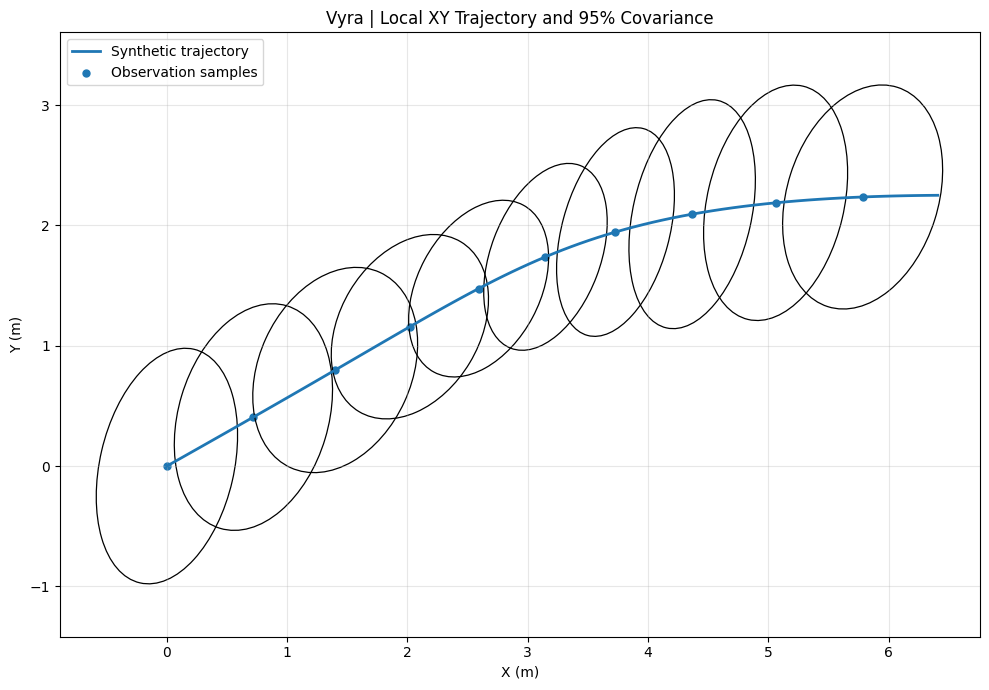

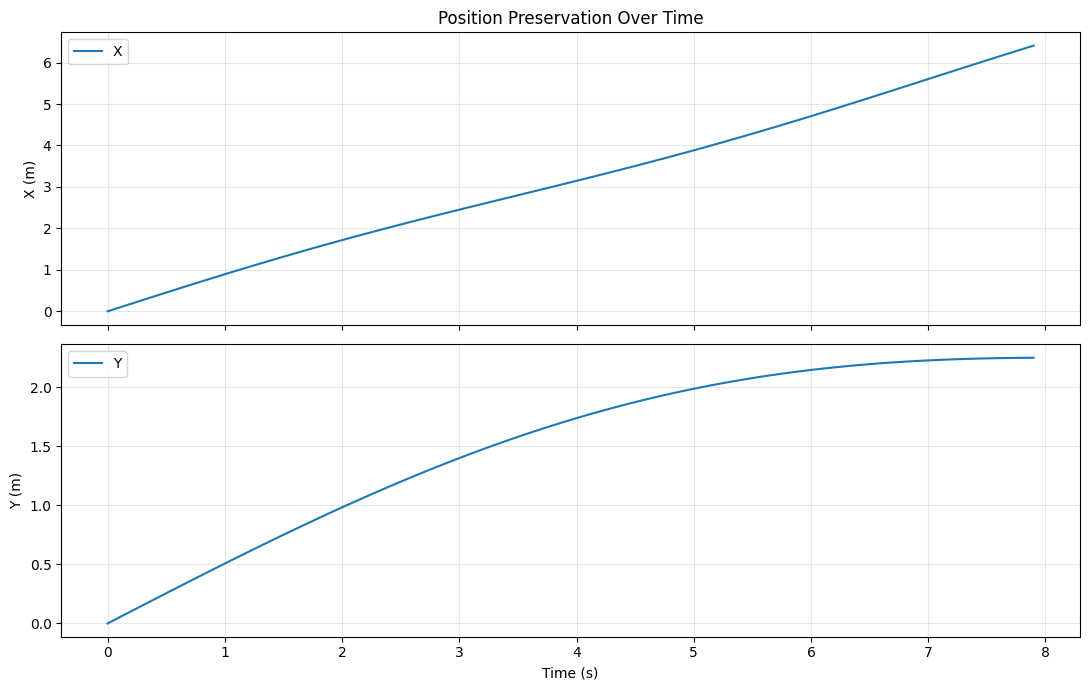

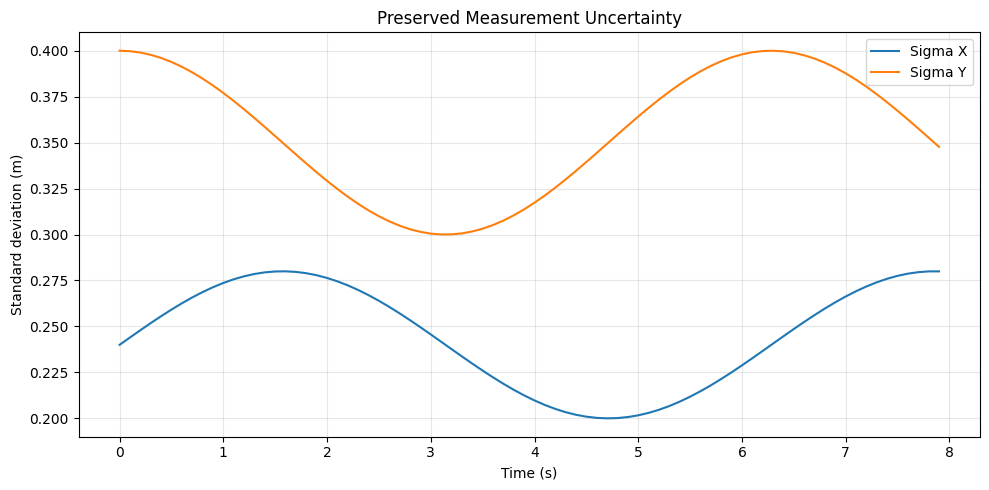

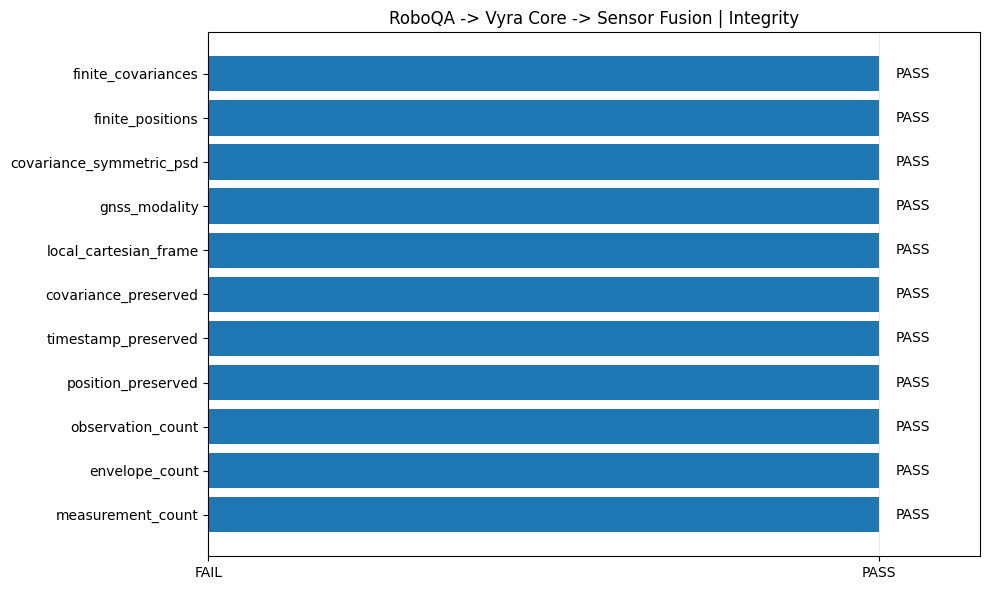


[7] EXPORTANDO CSV

[8] EMPACOTANDO RESULTADOS

VYRA VISUAL VALIDATION | FINAL SUMMARY
RoboQA: 7d8e77df75da236db2dc8c7199a146f12696ecb4
Vyra Core: 578b48f2fcd6d4e2a6079994e44dbf23b956f5d1
Sensor Fusion ML: fd4ff9ef40469023487be0571e44886fb6330088

Integrity: 11 / 11 PASS

Artifacts:
01_xy_trajectory_covariance.png (198,096 bytes)
02_position_over_time.png (82,843 bytes)
03_uncertainty_over_time.png (104,769 bytes)
04_integrity_checks.png (101,710 bytes)
integration_measurements.csv (11,856 bytes)
validation_report.json (1,310 bytes)

ZIP: /content/vyra_visual_validation/vyra_visual_validation_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:


# =====================================================================
# ARQTECH LABS | VYRA ECOSYSTEM
# ROBOQA -> VYRA CORE -> SENSOR FUSION ML
# MANUAL VISUAL VALIDATION | GOOGLE COLAB
#
# Reutiliza clones e instalações existentes.
# Não altera GitHub, não faz commit, não treina modelos.
# =====================================================================

import sys
import os
import json
import math
import csv
import zipfile
import subprocess
import importlib
import importlib.util

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# =====================================================================
# 0. PATHS
# =====================================================================

BASE = Path("/content/vyra_visual_validation")

ROBOQA = BASE / "roboqa"
CORE = BASE / "core"
FUSION = BASE / "fusion"

OUTPUT = BASE / "artifacts"
OUTPUT.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("ARQTECH LABS | VYRA VISUAL VALIDATION")
print("=" * 72)

for name, path in [
    ("RoboQA", ROBOQA),
    ("Vyra Core", CORE),
    ("Sensor Fusion ML", FUSION),
]:
    print(f"{name}: {path} | exists={path.exists()}")
    if not path.exists():
        raise FileNotFoundError(f"Repositório ausente: {path}")

# =====================================================================
# 1. REPOSITORY COMMITS
# =====================================================================

def get_head(path):
    return subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=path,
        text=True
    ).strip()

commits = {
    "roboqa": get_head(ROBOQA),
    "vyra_core": get_head(CORE),
    "sensor_fusion_ml": get_head(FUSION),
}

print("\n[1] COMMITS")
for name, sha in commits.items():
    print(name, sha)

# =====================================================================
# 2. IMPORT PATHS — EXPLICIT CHECKOUT PRIORITY
# =====================================================================

print("\n[2] CONFIGURANDO IMPORTS")

CORE_SRC = CORE / "src"
FUSION_SRC = FUSION / "src"
ROBOQA_SRC = ROBOQA

required_paths = [
    CORE_SRC / "vyra_core",
    FUSION_SRC / "sensor_fusion_ml",
    ROBOQA_SRC / "roboqa",
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Pacote não encontrado: {path}")

# Evita carregar módulos de checkouts antigos.
for module_name in list(sys.modules):
    if (
        module_name == "vyra_core"
        or module_name.startswith("vyra_core.")
        or module_name == "sensor_fusion_ml"
        or module_name.startswith("sensor_fusion_ml.")
    ):
        del sys.modules[module_name]

# Prioriza os três checkouts corretos.
priority_paths = [
    str(FUSION_SRC),
    str(CORE_SRC),
    str(ROBOQA_SRC),
]

sys.path = [
    p for p in sys.path
    if p not in priority_paths
    and "vyra_core_validation" not in p
]

for path in reversed(priority_paths):
    sys.path.insert(0, path)

importlib.invalidate_caches()

# =====================================================================
# 3. IMPORT REAL ADAPTERS
# =====================================================================

print("\n[3] IMPORTANDO ADAPTERS")

from roboqa.data.schemas import Measurement

from vyra_core.adapters.roboqa import (
    RoboQAGPSProducerAdapter
)

from vyra_core.contracts import (
    TemporalReference,
    SpatialReference
)

from sensor_fusion_ml.integrations.vyra_core import (
    roboqa_gps_envelope_to_observation
)

import vyra_core
import sensor_fusion_ml

print("Vyra Core:", vyra_core.__file__)
print("Sensor Fusion:", sensor_fusion_ml.__file__)

assert str(CORE) in str(vyra_core.__file__)
assert str(FUSION) in str(sensor_fusion_ml.__file__)

print("[PASS] Producer adapter")
print("[PASS] Consumer adapter")
print("[PASS] Imports from expected repositories")

# =====================================================================
# 4. CONTROLLED SYNTHETIC DATA
# =====================================================================

print("\n[4] GERANDO EXPERIMENTO SINTÉTICO")

N = 80

times = np.linspace(0.0, 7.9, N)

x_values = (
    0.8 * times
    + 0.12 * np.sin(0.9 * times)
)

y_values = (
    0.25 * times
    + 0.75 * np.sin(0.35 * times)
)

measurements = []
envelopes = []
observations = []

for i, t in enumerate(times):

    position = np.array(
        [x_values[i], y_values[i]],
        dtype=np.float64
    )

    sigma_x = 0.20 + 0.04 * (1 + math.sin(t))
    sigma_y = 0.30 + 0.05 * (1 + math.cos(t))

    covariance = np.array([
        [sigma_x**2, 0.025],
        [0.025, sigma_y**2]
    ], dtype=np.float64)

    measurement = Measurement(
        t=float(t),
        sensor="gps",
        z=position,
        R=covariance
    )

    temporal = TemporalReference(
        event_time=float(t),
        event_time_unit="seconds",
        time_reference="simulation_elapsed_seconds",
        clock_domain="roboqa_synthetic_clock",
        source_id="roboqa-lab-synthetic",
        sequence=i
    )

    spatial = SpatialReference(
        coordinate_frame="LOCAL_CARTESIAN",
        coordinate_system="local_cartesian_xy",
        crs="LOCAL:ARQTECH:SIMULATION",
        axis_order=("x", "y"),
        units=("m", "m"),
        origin="synthetic_origin_x0_y0"
    )

    producer = RoboQAGPSProducerAdapter(
        artifact_id=f"vyra-gps-{i:04d}",
        source_artifact_id=f"roboqa-measurement-{i:04d}",
        temporal_reference=temporal,
        spatial_reference=spatial
    )

    envelope = producer.to_envelope(measurement)

    observation = roboqa_gps_envelope_to_observation(
        envelope
    )

    measurements.append(measurement)
    envelopes.append(envelope)
    observations.append(observation)

print("Measurements:", len(measurements))
print("Envelopes:", len(envelopes))
print("Observations:", len(observations))

# =====================================================================
# 5. EXTRACT OUTPUTS
# =====================================================================

positions = np.array([
    np.asarray(o.data, dtype=float)
    for o in observations
])

covariances = np.array([
    np.asarray(
        o.metadata["measurement_covariance"],
        dtype=float
    )
    for o in observations
])

std_x = np.sqrt(covariances[:, 0, 0])
std_y = np.sqrt(covariances[:, 1, 1])

# =====================================================================
# 6. INTEGRITY VALIDATION
# =====================================================================

print("\n[5] VALIDANDO INTEGRIDADE")

checks = {
    "measurement_count": len(measurements) == N,
    "envelope_count": len(envelopes) == N,
    "observation_count": len(observations) == N,

    "position_preserved": all(
        np.array_equal(
            np.asarray(m.z),
            np.asarray(o.data)
        )
        for m, o in zip(measurements, observations)
    ),

    "timestamp_preserved": all(
        float(m.t) == float(o.timestamp.value)
        for m, o in zip(measurements, observations)
    ),

    "covariance_preserved": all(
        np.array_equal(
            np.asarray(m.R),
            np.asarray(o.metadata["measurement_covariance"])
        )
        for m, o in zip(measurements, observations)
    ),

    "local_cartesian_frame": all(
        o.frame.value == "local_cartesian"
        for o in observations
    ),

    "gnss_modality": all(
        o.modality.value == "gnss"
        for o in observations
    ),

    "covariance_symmetric_psd": all(
        np.allclose(m.R, m.R.T, atol=1e-8)
        and np.linalg.eigvalsh(m.R).min() >= -1e-8
        for m in measurements
    ),

    "finite_positions": bool(
        np.all(np.isfinite(positions))
    ),

    "finite_covariances": bool(
        np.all(np.isfinite(covariances))
    ),
}

for name, passed in checks.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

if not all(checks.values()):
    raise AssertionError(
        "A validação de integridade apresentou falhas."
    )

# =====================================================================
# 7. GRAPH 1 — XY TRAJECTORY + 95% COVARIANCE
# =====================================================================

print("\n[6] GERANDO GRÁFICOS")

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(
    positions[:, 0],
    positions[:, 1],
    linewidth=2,
    label="Synthetic trajectory"
)

ax.scatter(
    positions[::8, 0],
    positions[::8, 1],
    s=25,
    label="Observation samples"
)

for i in range(0, N, 8):

    eigenvalues, eigenvectors = np.linalg.eigh(
        covariances[i]
    )

    order = np.argsort(eigenvalues)[::-1]

    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(
        np.arctan2(
            eigenvectors[1, 0],
            eigenvectors[0, 0]
        )
    )

    width, height = (
        2 * np.sqrt(
            np.maximum(eigenvalues, 0) * 5.991
        )
    )

    ax.add_patch(Ellipse(
        xy=positions[i],
        width=width,
        height=height,
        angle=angle,
        fill=False,
        linewidth=0.9
    ))

ax.set_title(
    "Vyra | Local XY Trajectory and 95% Covariance"
)

ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.axis("equal")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT / "01_xy_trajectory_covariance.png",
    dpi=180
)

plt.show()
plt.close(fig)

# =====================================================================
# 8. GRAPH 2 — POSITION OVER TIME
# =====================================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True
)

axes[0].plot(
    times,
    positions[:, 0],
    label="X"
)

axes[0].set_ylabel("X (m)")
axes[0].set_title("Position Preservation Over Time")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    times,
    positions[:, 1],
    label="Y"
)

axes[1].set_ylabel("Y (m)")
axes[1].set_xlabel("Time (s)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.tight_layout()

fig.savefig(
    OUTPUT / "02_position_over_time.png",
    dpi=180
)

plt.show()
plt.close(fig)

# =====================================================================
# 9. GRAPH 3 — UNCERTAINTY
# =====================================================================

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    times,
    std_x,
    label="Sigma X"
)

ax.plot(
    times,
    std_y,
    label="Sigma Y"
)

ax.set_title(
    "Preserved Measurement Uncertainty"
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Standard deviation (m)")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT / "03_uncertainty_over_time.png",
    dpi=180
)

plt.show()
plt.close(fig)

# =====================================================================
# 10. GRAPH 4 — INTEGRITY CHECKS
# =====================================================================

fig, ax = plt.subplots(figsize=(10, 6))

names = list(checks.keys())
values = [
    int(checks[name])
    for name in names
]

ax.barh(names, values)

ax.set_xlim(0, 1.15)
ax.set_xticks(
    [0, 1],
    ["FAIL", "PASS"]
)

ax.set_title(
    "RoboQA -> Vyra Core -> Sensor Fusion | Integrity"
)

for i, value in enumerate(values):
    ax.text(
        value + 0.025,
        i,
        "PASS" if value else "FAIL",
        va="center"
    )

ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

fig.savefig(
    OUTPUT / "04_integrity_checks.png",
    dpi=180
)

plt.show()
plt.close(fig)

# =====================================================================
# 11. CSV EXPORT
# =====================================================================

print("\n[7] EXPORTANDO CSV")

csv_path = OUTPUT / "integration_measurements.csv"

with open(
    csv_path,
    "w",
    newline=""
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "index",
        "timestamp_s",
        "x_input_m",
        "y_input_m",
        "x_output_m",
        "y_output_m",
        "sigma_x_m",
        "sigma_y_m",
        "coordinate_frame",
        "modality"
    ])

    for i, (m, o) in enumerate(
        zip(measurements, observations)
    ):

        writer.writerow([
            i,
            m.t,
            m.z[0],
            m.z[1],
            o.data[0],
            o.data[1],
            std_x[i],
            std_y[i],
            o.frame.value,
            o.modality.value
        ])

# =====================================================================
# 12. JSON REPORT
# =====================================================================

report = {
    "project": "Vyra Ecosystem",
    "organization": "ArqTech Labs",

    "experiment": (
        "RoboQA -> Vyra Core -> Sensor Fusion ML"
    ),

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "data_type": "synthetic_controlled_measurements",
    "sample_count": N,

    "source_commits": commits,

    "previous_automated_test_results": {
        "consumer_integration": "10 passed",
        "sensor_fusion_full_suite": "86 passed",
        "vyra_core_suite": "passed, exit code 0"
    },

    "integrity_checks": checks,

    "limitations": [
        "Synthetic data, not physical sensor measurements.",
        "No geographic coordinate transformation.",
        "No Kalman filter update.",
        "No sensor fusion estimation.",
        "Covariance preserved in metadata, not consumed by Kalman.",
        "No model training."
    ]
}

with open(
    OUTPUT / "validation_report.json",
    "w"
) as f:
    json.dump(
        report,
        f,
        indent=2
    )

# =====================================================================
# 13. PACKAGE RESULTS
# =====================================================================

print("\n[8] EMPACOTANDO RESULTADOS")

ZIP_PATH = BASE / "vyra_visual_validation_artifacts.zip"

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for file in OUTPUT.iterdir():
        if file.is_file():
            archive.write(
                file,
                arcname=file.name
            )

# =====================================================================
# 14. FINAL REPORT
# =====================================================================

print("\n" + "=" * 72)
print("VYRA VISUAL VALIDATION | FINAL SUMMARY")
print("=" * 72)

print("RoboQA:", commits["roboqa"])
print("Vyra Core:", commits["vyra_core"])
print("Sensor Fusion ML:", commits["sensor_fusion_ml"])

print(
    "\nIntegrity:",
    sum(checks.values()),
    "/",
    len(checks),
    "PASS"
)

print("\nArtifacts:")

for file in sorted(OUTPUT.iterdir()):
    print(
        file.name,
        f"({file.stat().st_size:,} bytes)"
    )

print("\nZIP:", ZIP_PATH)
print("=" * 72)

# =====================================================================
# 15. DOWNLOAD
# =====================================================================

try:
    from google.colab import files
    files.download(str(ZIP_PATH))
except Exception as exc:
    print(
        "Download automático indisponível:",
        repr(exc)
    )
    print("Arquivo salvo em:", ZIP_PATH)

In [26]:


# =====================================================================
# ARQTECH LABS | VYRA MILESTONE 002
# REAL DATA INTEGRATION READINESS
# READ-ONLY AUDIT | NO DOWNLOAD | NO TRAINING | NO REPOSITORY CHANGES
# =====================================================================

from pathlib import Path
import subprocess
import re
import json

BASE = Path("/content/vyra_visual_validation")

REPOS = {
    "ROBOQA": BASE / "roboqa",
    "VYRA_CORE": BASE / "core",
    "SENSOR_FUSION_ML": BASE / "fusion",
}

print("=" * 72)
print("VYRA | MILESTONE 002 | READINESS AUDIT")
print("=" * 72)

# --------------------------------------------------
# 1. REPOSITORY IDENTITY
# --------------------------------------------------

print("\n[1] REPOSITORY IDENTITY")

for name, path in REPOS.items():

    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

    if not path.exists():
        continue

    head = subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=path,
        text=True
    ).strip()

    branch = subprocess.check_output(
        ["git", "branch", "--show-current"],
        cwd=path,
        text=True
    ).strip()

    status = subprocess.check_output(
        ["git", "status", "--short"],
        cwd=path,
        text=True
    ).strip()

    print("Branch:", branch)
    print("HEAD:", head)
    print("Working tree:", "CLEAN" if not status else "MODIFIED")
    if status:
        print(status)

# --------------------------------------------------
# 2. ROBOQA OXTS / KITTI SOURCE AUDIT
# --------------------------------------------------

print("\n[2] ROBOQA SOURCE AUDIT")

ROBOQA = REPOS["ROBOQA"]

patterns = re.compile(
    r"kitti|oxts|gps|latitude|longitude|"
    r"timestamp|covariance|measurement|"
    r"coordinate|projection|wgs84",
    re.IGNORECASE
)

source_matches = []

if ROBOQA.exists():

    for file in ROBOQA.rglob("*.py"):

        try:
            lines = file.read_text(
                encoding="utf-8",
                errors="replace"
            ).splitlines()
        except Exception:
            continue

        for line_number, line in enumerate(lines, 1):

            if patterns.search(line):
                source_matches.append({
                    "file": str(file.relative_to(ROBOQA)),
                    "line": line_number,
                    "text": line.strip()[:220]
                })

print("Matching source lines:", len(source_matches))

for item in source_matches[:100]:
    print(
        f"{item['file']}:{item['line']} | "
        f"{item['text']}"
    )

if len(source_matches) > 100:
    print("Output limitado aos primeiros 100 resultados.")

# --------------------------------------------------
# 3. MEASUREMENT SCHEMA
# --------------------------------------------------

print("\n[3] ROBOQA MEASUREMENT SCHEMA")

schema_file = ROBOQA / "roboqa" / "data" / "schemas.py"

print("Schema path:", schema_file)
print("Exists:", schema_file.exists())

if schema_file.exists():

    lines = schema_file.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for i, line in enumerate(lines):

        if re.search(r"class Measurement\b", line):

            start = max(0, i - 3)
            end = min(len(lines), i + 65)

            print("\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(start, end)
            ))
            break

# --------------------------------------------------
# 4. PRODUCER ADAPTER CONTRACT
# --------------------------------------------------

print("\n[4] VYRA CORE PRODUCER")

producer_file = (
    REPOS["VYRA_CORE"]
    / "src" / "vyra_core" / "adapters" / "roboqa.py"
)

print("Producer:", producer_file)
print("Exists:", producer_file.exists())

if producer_file.exists():

    lines = producer_file.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for i, line in enumerate(lines):

        if "class RoboQAGPSProducerAdapter" in line:

            end = min(len(lines), i + 115)

            print("\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(i, end)
            ))
            break

# --------------------------------------------------
# 5. SENSOR FUSION CONSUMER CONTRACT
# --------------------------------------------------

print("\n[5] SENSOR FUSION CONSUMER")

consumer_file = (
    REPOS["SENSOR_FUSION_ML"]
    / "src" / "sensor_fusion_ml"
    / "integrations" / "vyra_core.py"
)

print("Consumer:", consumer_file)
print("Exists:", consumer_file.exists())

if consumer_file.exists():

    lines = consumer_file.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for i, line in enumerate(lines):

        if "def roboqa_gps_envelope_to_observation" in line:

            end = min(len(lines), i + 120)

            print("\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(i, end)
            ))
            break

# --------------------------------------------------
# 6. DATASET AVAILABILITY
# --------------------------------------------------

print("\n[6] KITTI / OXTS DATA AVAILABILITY")

DATA_ROOTS = [
    Path("/content/datasets"),
    Path("/content/dataset"),
    Path("/content/data"),
    Path("/content/kitti"),
    Path("/content/KITTI"),
    Path("/content/drive/MyDrive/datasets"),
    Path("/content/drive/MyDrive/KITTI"),
]

found_directories = []
found_oxts_files = []

for root in DATA_ROOTS:

    if not root.exists():
        continue

    print("\nSearching:", root)

    try:
        for directory in root.rglob("*"):

            if not directory.is_dir():
                continue

            if directory.name.lower() == "oxts":
                found_directories.append(directory)

                print("OXTS directory:", directory)

                data_dir = directory / "data"

                if data_dir.exists():

                    files = sorted(data_dir.glob("*.txt"))

                    for file in files[:10]:
                        found_oxts_files.append(file)
                        print("  Data file:", file.name)

                    print(
                        "  TXT files found:",
                        len(files)
                    )

    except PermissionError:
        print("Permission denied:", root)

print("\nOXTS directories:", len(found_directories))
print("Sample OXTS files:", len(found_oxts_files))

# --------------------------------------------------
# 7. SUMMARY
# --------------------------------------------------

print("\n[7] AUDIT SUMMARY")

summary = {
    "repositories_present": all(
        p.exists() for p in REPOS.values()
    ),
    "roboqa_schema_present": schema_file.exists(),
    "producer_adapter_present": producer_file.exists(),
    "consumer_adapter_present": consumer_file.exists(),
    "oxts_directory_found": len(found_directories) > 0,
    "oxts_sample_files_found": len(found_oxts_files) > 0,
}

for name, value in summary.items():
    print(
        f"[{'FOUND' if value else 'NOT FOUND'}] {name}"
    )

print("\nREAD-ONLY AUDIT COMPLETE")
print("No repository files were modified.")
print("No datasets were downloaded.")
print("No training or inference was executed.")

print("=" * 72)

VYRA | MILESTONE 002 | READINESS AUDIT

[1] REPOSITORY IDENTITY

ROBOQA
Path: /content/vyra_visual_validation/roboqa
Exists: True
Branch: main
HEAD: 7d8e77df75da236db2dc8c7199a146f12696ecb4
Working tree: MODIFIED
?? roboqa/__pycache__/
?? roboqa/data/__pycache__/

VYRA_CORE
Path: /content/vyra_visual_validation/core
Exists: True
Branch: main
HEAD: 578b48f2fcd6d4e2a6079994e44dbf23b956f5d1
Working tree: MODIFIED
?? src/vyra_core.egg-info/
?? src/vyra_core/__pycache__/
?? src/vyra_core/adapters/__pycache__/
?? src/vyra_core/contracts/__pycache__/
?? src/vyra_core/validation/__pycache__/
?? tests/adapters/__pycache__/
?? tests/contracts/__pycache__/
?? tests/validation/__pycache__/

SENSOR_FUSION_ML
Path: /content/vyra_visual_validation/fusion
Exists: True
Branch: main
HEAD: fd4ff9ef40469023487be0571e44886fb6330088
Working tree: CLEAN

[2] ROBOQA SOURCE AUDIT
Matching source lines: 243
roboqa/__init__.py:11 | Measurement,
roboqa/__init__.py:19 | "Measurement",
tests/adversarial/test_data_a

In [27]:


# =====================================================================
# VYRA | MILESTONE 002.1
# KITTI OXTS SOURCE & COORDINATE TRANSFORM AUDIT
# READ-ONLY
# =====================================================================

from pathlib import Path
import ast
import subprocess

ROBOQA = Path("/content/vyra_visual_validation/roboqa")
KITTI_FILE = ROBOQA / "roboqa" / "data" / "kitti.py"

print("=" * 72)
print("VYRA | KITTI SOURCE AUDIT")
print("=" * 72)

# 1. Inspect actual KITTI implementation
print("\n[1] KITTI IMPLEMENTATION")
print("File:", KITTI_FILE)
print("Exists:", KITTI_FILE.exists())

if KITTI_FILE.exists():
    source = KITTI_FILE.read_text(
        encoding="utf-8",
        errors="replace"
    )

    tree = ast.parse(source)

    targets = {
        "load_kitti_oxts",
        "latlon_to_local",
        "get_trajectory",
        "download_kitti_drive",
    }

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in targets:
                print("\n" + "-" * 72)
                print(f"FUNCTION: {node.name}")
                print("-" * 72)
                print(ast.get_source_segment(source, node))

# 2. Inspect KITTI-related configuration and documentation
print("\n[2] KITTI REFERENCES")

for folder in ["roboqa", "tests", "docs"]:
    root = ROBOQA / folder

    if not root.exists():
        continue

    for file in root.rglob("*"):
        if not file.is_file():
            continue

        if file.suffix.lower() not in {
            ".py", ".md", ".yaml", ".yml", ".toml", ".json"
        }:
            continue

        try:
            content = file.read_text(
                encoding="utf-8",
                errors="replace"
            )
        except Exception:
            continue

        matches = [
            (i, line.strip())
            for i, line in enumerate(content.splitlines(), 1)
            if any(term in line.lower() for term in (
                "kitti", "oxts", "latlon_to_local",
                "kitti_real", "sequence"
            ))
        ]

        if matches:
            print(f"\nFILE: {file.relative_to(ROBOQA)}")
            for line_number, line in matches[:20]:
                print(f"{line_number}: {line[:220]}")

# 3. Check common dataset locations without downloading
print("\n[3] DATASET LOCATION CHECK")

roots = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
]

for root in roots:
    print(f"\nROOT: {root} | exists={root.exists()}")

    if not root.exists():
        continue

    candidates = []

    for item in root.iterdir():
        if not item.is_dir():
            continue

        name = item.name.lower()

        if any(term in name for term in (
            "kitti", "dataset", "oxts", "odometry"
        )):
            candidates.append(item)

    if candidates:
        for item in candidates:
            print("CANDIDATE:", item)
    else:
        print("No obvious KITTI/dataset directory at this level.")

# 4. Check whether Google Drive is mounted
print("\n[4] GOOGLE DRIVE")
drive = Path("/content/drive/MyDrive")
print("Mounted:", drive.exists())

print("\n" + "=" * 72)
print("AUDIT COMPLETE — NO DOWNLOAD OR SOURCE MODIFICATION")
print("=" * 72)

VYRA | KITTI SOURCE AUDIT

[1] KITTI IMPLEMENTATION
File: /content/vyra_visual_validation/roboqa/roboqa/data/kitti.py
Exists: True

------------------------------------------------------------------------
FUNCTION: latlon_to_local
------------------------------------------------------------------------
def latlon_to_local(
    lat: np.ndarray,
    lon: np.ndarray,
    lat0: Optional[float] = None,
    lon0: Optional[float] = None,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Converte latitude/longitude (graus) para coordenadas cartesianas locais (m).

    Utiliza aproximação equiretangular (adequada para trajetórias curtas,
    < ~10 km). Referência: centro da primeira amostra ou (lat0, lon0) fornecidos.

    Raises
    ------
    SchemaError
        Em entradas vazias, não-finitas ou dimensionalmente incompatíveis.
    """
    lat = np.asarray(lat, dtype=np.float64)
    lon = np.asarray(lon, dtype=np.float64)

    if lat.size == 0 or lon.size == 0:
        raise SchemaError("lat/lo

In [28]:


from pathlib import Path
import os

roots = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
    Path("/content/drive/Shareddrives"),
]

# Monta o Google Drive se necessário.
try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception as e:
    print("Drive não montado:", repr(e))

roots = [p for p in roots if p.exists()]

print("=" * 65)
print("VYRA | KITTI DATASET LOCATOR — READ ONLY")
print("=" * 65)

found = set()

for root in roots:
    print(f"\nPesquisando: {root}")

    for current, dirs, files in os.walk(root):
        # Evita caches e diretórios de sistema desnecessários.
        dirs[:] = [
            d for d in dirs
            if d not in {
                ".git", "__pycache__", ".cache",
                "node_modules", ".config"
            }
        ]

        current_path = Path(current)

        if "kitti" in str(current_path).lower():
            found.add(str(current_path))

        for filename in files:
            path = current_path / filename
            name = filename.lower()

            if "kitti" in name or (
                name.endswith(".zip") and
                any(x in str(path).lower()
                    for x in ["kitti", "dataset", "datasets"])
            ):
                found.add(str(path))

        if current_path.name.lower() == "oxts":
            if (current_path / "data").exists():
                found.add(str(current_path))

print("\n" + "=" * 65)
print("RESULTADO")
print("=" * 65)

if found:
    for item in sorted(found):
        print("[FOUND]", item)
else:
    print("Nenhum arquivo ou diretório KITTI identificado.")

Mounted at /content/drive
VYRA | KITTI DATASET LOCATOR — READ ONLY

Pesquisando: /content

Pesquisando: /content/drive/MyDrive

RESULTADO
[FOUND] /content/vyra_visual_validation/roboqa/roboqa/data/kitti.py


In [29]:


from pathlib import Path

root = Path("/content/vyra_visual_validation/roboqa")

print("DIRETÓRIO:", root)
print("EXISTE:", root.exists())

if root.exists():
    for p in sorted(root.rglob("*")):
        if p.is_file():
            name = p.name.lower()
            if (
                "kitti" in str(p).lower()
                or "oxts" in name
                or name.endswith((".zip", ".tar", ".tar.gz"))
            ):
                print(
                    f"{p} | "
                    f"{p.stat().st_size / (1024**2):.2f} MB"
                )

DIRETÓRIO: /content/vyra_visual_validation/roboqa
EXISTE: True
/content/vyra_visual_validation/roboqa/roboqa/data/__pycache__/kitti.cpython-313.pyc | 0.01 MB
/content/vyra_visual_validation/roboqa/roboqa/data/kitti.py | 0.01 MB


In [30]:


from pathlib import Path
import os

base = Path("/content/vyra_visual_validation/roboqa/roboqa/data/kitti.py")

print("=" * 65)
print("1. CONTRATO DO LOADER KITTI")
print("=" * 65)

if base.exists():
    print(base.read_text())
else:
    print("Loader não encontrado.")

print("\n" + "=" * 65)
print("2. ARQUIVOS E DIRETÓRIOS DE DATASET")
print("=" * 65)

roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

archives = []
oxts_dirs = []

for root in roots:
    if not root.exists():
        continue

    for current, dirs, files in os.walk(root):
        dirs[:] = [
            d for d in dirs
            if d not in {".git", "__pycache__", "node_modules"}
        ]

        current = Path(current)

        if current.name.lower() == "oxts":
            if (current / "data").exists():
                oxts_dirs.append(current)

        for f in files:
            p = current / f
            if f.lower().endswith((".zip", ".7z", ".tar", ".gz")):
                try:
                    archives.append((p, p.stat().st_size))
                except OSError:
                    pass

print("\nDiretórios OXTS encontrados:")
for p in oxts_dirs:
    print(p)

print("\nArquivos compactados encontrados:")
for p, size in sorted(archives, key=lambda x: x[1], reverse=True):
    print(f"{size / (1024**3):.2f} GiB | {p}")

print("\nVerificação concluída. Nenhum arquivo foi alterado.")

1. CONTRATO DO LOADER KITTI
"""
Carregador de trajetórias KITTI OXTS.
Fase 1 — Data Engine (hardened)
ARQTECH LABS

Política de proveniência e fallback:
- load_kitti_oxts() levanta SchemaError em qualquer falha.
- get_trajectory(prefer_kitti=True) NÃO faz fallback silencioso.
  Se o caminho for inválido ou a leitura falhar, a exceção propaga.
- Fallback sintético ocorre somente quando prefer_kitti=False
  ou quando kitti_path é None.
- download_kitti_drive() é opt-in e, por política de segurança (R7),
  levanta NotImplementedError (sem download automático).

Temporalidade:
- Quando timestamps reais não estão disponíveis nos arquivos .txt
  do OXTS (formato clássico), usa-se aproximação de 10 Hz (dt=0.1 s).
- Esta aproximação é documentada e identificada.
- yaw_rate é calculado via np.gradient com np.unwrap para respeitar
  a descontinuidade angular.
"""

from __future__ import annotations

from pathlib import Path
from typing import Optional, Tuple, Union

import numpy as np

from .sch

ARQTECH LABS | VYRA — PPC DATASET VALIDATION
Dataset: https://github.com/taroz/PPC-Dataset
Target: Nagoya / run1
Output: /content/vyra_ppc_validation

[1/9] Download do OneDrive...
Tentando: https://chibakoudai-my.sharepoint.com/:u:/g/personal/66lsm6_chibatech_ac_jp/ETmyNr1VrcpFjqxgjXJdgkQB ...
Download concluído: 154.73111152648926 MB
URL final: https://chibakoudai-my.sharepoint.com/personal/66lsm6_chibatech_ac_jp/Documents/PPC-Dataset.zip?ga=1

[2/9] Integridade do arquivo...
SHA256: 460b21747a78c8cca60190895b32615b9943cf4f75a20864280bb86a01b76658
CRC: PASS
Membros: 133
Tamanho extraído: 796.27 MB

[3/9] Extraindo dataset...
Extraídos 100/133

[4/9] Localizando sequências...
PPC-Dataset/README.md
PPC-Dataset/.gitignore
PPC-Dataset/.gitattributes
PPC-Dataset/LICENSE
PPC-Dataset/nagoya/README.md
PPC-Dataset/tokyo/README.md
PPC-Dataset/.git/description
PPC-Dataset/.git/COMMIT_EDITMSG
PPC-Dataset/.git/index
PPC-Dataset/.git/config
PPC-Dataset/.git/HEAD
PPC-Dataset/.git/FETCH_HEAD
PPC-Dat

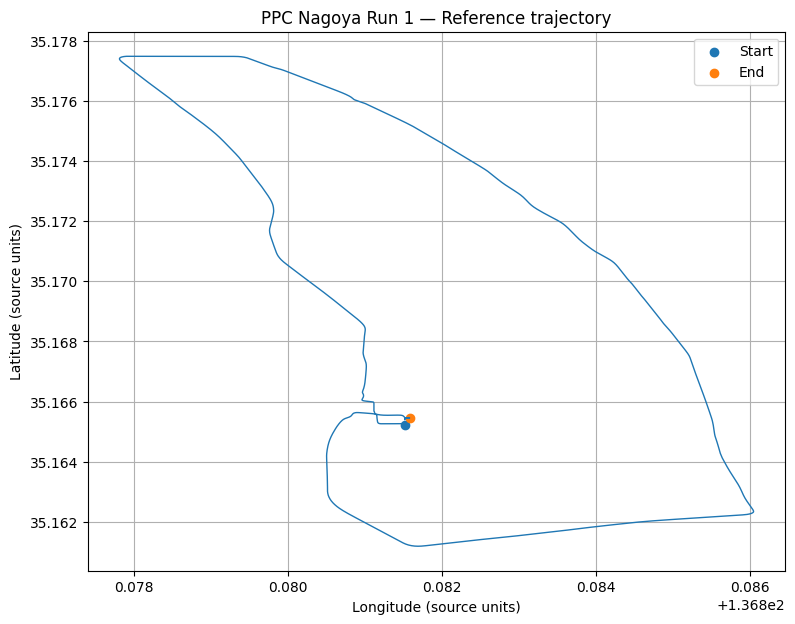

Trajectory plot: /content/vyra_ppc_validation/audit/nagoya_run1_reference_trajectory.png

[8/9] Executando testes...
PASS zip_exists = True
PASS zip_crc_pass = True
PASS extraction_marker_matches = True
PASS nagoya_run1_files_present = True
PASS imu.csv_nonempty = True
PASS imu.csv_columns_present = True
PASS imu.csv_no_duplicate_rows = True
PASS reference.csv_nonempty = True
PASS reference.csv_columns_present = True
PASS reference.csv_no_duplicate_rows = True
PASS rover.obs_header_valid = True
PASS rover.obs_rinex_version_detected = True
PASS base.obs_header_valid = True
PASS base.obs_rinex_version_detected = True
PASS base.nav_header_valid = True
PASS base.nav_rinex_version_detected = True
PASS reference_coordinate_candidates_found = True
PASS trajectory_plot_generated = True

[9/9] Salvando relatórios...

VYRA | PPC VALIDATION SUMMARY
Tests: 18/18
Status: PASS
Dataset: /content/vyra_ppc_validation/dataset
Report: /content/vyra_ppc_validation/audit/validation_report.json
CSV schema: 

In [31]:


# ================================================================
# ARQTECH LABS | VYRA
# PPC DATASET — DOWNLOAD, AUDIT, VALIDATION AND TESTS
# Source: https://github.com/taroz/PPC-Dataset
# Target: Nagoya / Run 1
#
# No GitHub modifications, no model training, no fabricated metrics.
# ================================================================

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import os, re, json, hashlib, zipfile, shutil, base64, io
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("/content/vyra_ppc_validation")
DOWNLOADS = ROOT / "downloads"
EXTRACT = ROOT / "dataset"
AUDIT = ROOT / "audit"

for p in [DOWNLOADS, EXTRACT, AUDIT]:
    p.mkdir(parents=True, exist_ok=True)

# Link público publicado no README oficial.
SHARE_URL = (
    "https://chibakoudai-my.sharepoint.com/:u:/g/personal/"
    "66lsm6_chibatech_ac_jp/"
    "ETmyNr1VrcpFjqxgjXJdgkQBkfTwnykhSPOVKClOUBNOMQ"
)

REPO = "https://github.com/taroz/PPC-Dataset"
ZIP_PATH = DOWNLOADS / "PPC-Dataset.zip"

print("=" * 72)
print("ARQTECH LABS | VYRA — PPC DATASET VALIDATION")
print("=" * 72)
print("Dataset:", REPO)
print("Target: Nagoya / run1")
print("Output:", ROOT)

# ------------------------------------------------
# 1. DOWNLOAD — TRY PUBLIC ONEDRIVE ACCESS
# ------------------------------------------------

def download_stream(url, destination):
    with requests.get(
        url, stream=True, allow_redirects=True, timeout=(30, 120)
    ) as response:
        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "").lower()
        if "text/html" in content_type:
            raise RuntimeError(
                "OneDrive retornou uma página HTML, não o arquivo ZIP."
            )

        total = 0
        with open(destination, "wb") as f:
            for chunk in response.iter_content(8 * 1024 * 1024):
                if chunk:
                    f.write(chunk)
                    total += len(chunk)

        if total < 1024 * 1024:
            raise RuntimeError("Arquivo recebido é pequeno demais.")

        return total, response.url

print("\n[1/9] Download do OneDrive...")

if not ZIP_PATH.exists():
    urls = [
        SHARE_URL + "?download=1",
        SHARE_URL
    ]

    # Tentativa adicional pela API de compartilhamento Microsoft.
    encoded = base64.urlsafe_b64encode(
        SHARE_URL.encode()
    ).decode().rstrip("=")

    urls.append(
        f"https://api.onedrive.com/v1.0/shares/u!{encoded}/root/content"
    )

    errors = []
    success = False

    for url in urls:
        try:
            print("Tentando:", url[:100], "...")
            size, final_url = download_stream(url, ZIP_PATH)

            if not zipfile.is_zipfile(ZIP_PATH):
                ZIP_PATH.unlink(missing_ok=True)
                raise RuntimeError("Resposta não é um ZIP válido.")

            print("Download concluído:", size / 1024**2, "MB")
            print("URL final:", final_url)
            success = True
            break

        except Exception as e:
            errors.append(repr(e))
            ZIP_PATH.unlink(missing_ok=True)
            print("Tentativa falhou:", repr(e))

    if not success:
        raise RuntimeError(
            "O OneDrive não permitiu download automatizado nesta sessão.\n"
            "Não foi criado um dataset fictício.\n"
            "Abra o link oficial e baixe o ZIP manualmente:\n"
            + SHARE_URL
            + "\nDepois envie o ZIP para /content/vyra_ppc_validation/downloads/"
              "PPC-Dataset.zip no Colab e execute novamente.\n\n"
            + "\n".join(errors)
        )
else:
    print("ZIP existente localizado:", ZIP_PATH)

# ------------------------------------------------
# 2. SHA256 + ZIP VALIDATION
# ------------------------------------------------

print("\n[2/9] Integridade do arquivo...")

sha = hashlib.sha256()
with open(ZIP_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        sha.update(chunk)

zip_sha256 = sha.hexdigest()

if not zipfile.is_zipfile(ZIP_PATH):
    raise RuntimeError("Arquivo não é ZIP.")

with zipfile.ZipFile(ZIP_PATH) as z:
    members = z.infolist()

    if not members:
        raise RuntimeError("ZIP vazio.")

    total_uncompressed = sum(
        x.file_size for x in members if not x.is_dir()
    )

    for item in members:
        p = PurePosixPath(item.filename)
        if p.is_absolute() or ".." in p.parts:
            raise RuntimeError("Caminho inseguro no ZIP: " + item.filename)

        mode = (item.external_attr >> 16) & 0o170000
        if mode == 0o120000:
            raise RuntimeError("Link simbólico não permitido.")

    bad = z.testzip()
    if bad:
        raise RuntimeError("CRC inválido: " + bad)

print("SHA256:", zip_sha256)
print("CRC: PASS")
print("Membros:", len(members))
print("Tamanho extraído:", round(total_uncompressed / 1024**2, 2), "MB")

# ------------------------------------------------
# 3. EXTRACTION
# ------------------------------------------------

print("\n[3/9] Extraindo dataset...")

marker = EXTRACT / "_EXTRACTION_COMPLETE.json"

if marker.exists():
    old = json.loads(marker.read_text())
    if old.get("sha256") != zip_sha256:
        raise RuntimeError(
            "Pasta de extração existente pertence a outro ZIP. "
            "Não será sobrescrita automaticamente."
        )
    print("Extração anterior validada pelo SHA256.")
else:
    if any(EXTRACT.iterdir()):
        raise RuntimeError(
            "Pasta de extração não vazia sem marcador de integridade. "
            "Use uma pasta limpa antes de prosseguir."
        )

    with zipfile.ZipFile(ZIP_PATH) as z:
        for i, item in enumerate(z.infolist(), 1):
            if item.is_dir():
                continue

            dest = EXTRACT.joinpath(*PurePosixPath(item.filename).parts)
            dest.parent.mkdir(parents=True, exist_ok=True)

            with z.open(item) as src, open(dest, "wb") as dst:
                shutil.copyfileobj(src, dst, 8 * 1024 * 1024)

            if i % 100 == 0:
                print(f"Extraídos {i}/{len(members)}")

    marker.write_text(json.dumps({
        "sha256": zip_sha256,
        "created_utc": datetime.now(timezone.utc).isoformat()
    }, indent=2))

# ------------------------------------------------
# 4. LOCATE RUNS AND REQUIRED FILES
# ------------------------------------------------

print("\n[4/9] Localizando sequências...")

all_files = [
    p for p in EXTRACT.rglob("*")
    if p.is_file() and p.name != marker.name
]

for p in all_files[:80]:
    print(p.relative_to(EXTRACT))

def locate(filename, city="nagoya", run="run1"):
    candidates = [
        p for p in all_files
        if p.name.lower() == filename.lower()
        and city in str(p).lower()
        and run in str(p).lower()
    ]
    return candidates[0] if len(candidates) == 1 else None

required = [
    "rover.obs",
    "base.obs",
    "base.nav",
    "imu.csv",
    "reference.csv"
]

run_files = {name: locate(name) for name in required}

print("\nArquivos de Nagoya/run1:")
for name, path in run_files.items():
    print(name, "=>", path if path else "NOT FOUND")

missing = [k for k, v in run_files.items() if v is None]

if missing:
    raise RuntimeError(
        "Arquivos obrigatórios ausentes em Nagoya/run1: "
        + ", ".join(missing)
        + ". Confira a estrutura extraída antes de adaptar o parser."
    )

# ------------------------------------------------
# 5. CSV SCHEMA AND DATA QUALITY
# ------------------------------------------------

print("\n[5/9] Inspecionando IMU e referência...")

csv_report = {}
loaded = {}

for name in ["imu.csv", "reference.csv"]:
    path = run_files[name]

    df = pd.read_csv(path, low_memory=False)
    loaded[name] = df

    numeric = df.select_dtypes(include=[np.number])
    null_counts = df.isna().sum().to_dict()

    csv_report[name] = {
        "path": str(path.relative_to(EXTRACT)),
        "rows": int(len(df)),
        "columns": list(df.columns),
        "dtypes": {k: str(v) for k, v in df.dtypes.items()},
        "null_counts": {k: int(v) for k, v in null_counts.items()},
        "numeric_columns": list(numeric.columns),
        "numeric_nonfinite": {
            c: int((~np.isfinite(numeric[c])).sum())
            for c in numeric.columns
        },
        "duplicate_rows": int(df.duplicated().sum())
    }

    print("\n", name)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print(df.head(5).to_string(index=False))

# ------------------------------------------------
# 6. RINEX HEADER AUDIT
# ------------------------------------------------

print("\n[6/9] Lendo cabeçalhos RINEX...")

def rinex_header(path):
    lines = []
    with open(path, "r", errors="replace") as f:
        for line in f:
            lines.append(line.rstrip())
            if "END OF HEADER" in line:
                break

    return {
        "path": str(path.relative_to(EXTRACT)),
        "header_lines": len(lines),
        "version": next(
            (x[:20].strip() for x in lines if "RINEX VERSION" in x),
            None
        ),
        "receiver": next(
            (x[:60].strip() for x in lines if "REC # / TYPE / VERS" in x),
            None
        ),
        "antenna": next(
            (x[:60].strip() for x in lines if "ANT # / TYPE" in x),
            None
        ),
        "first_lines": lines[:15],
        "has_end_of_header": any("END OF HEADER" in x for x in lines)
    }

rinex_report = {
    name: rinex_header(run_files[name])
    for name in ["rover.obs", "base.obs", "base.nav"]
}

for name, result in rinex_report.items():
    print("\n", name)
    print("Version:", result["version"])
    print("Header valid:", result["has_end_of_header"])

# ------------------------------------------------
# 7. BASIC TIMESTAMP AND TRAJECTORY DISCOVERY
# ------------------------------------------------

print("\n[7/9] Procurando colunas temporais e coordenadas...")

def find_column(columns, patterns):
    for c in columns:
        normalized = re.sub(r"[^a-z0-9]+", "_", str(c).lower()).strip("_")
        if any(re.search(p, normalized) for p in patterns):
            return c
    return None

reference = loaded["reference.csv"]
imu = loaded["imu.csv"]

time_candidates = {
    "reference": find_column(
        reference.columns,
        [r"^time$", r"timestamp", r"gps.*time", r"^tow$"]
    ),
    "imu": find_column(
        imu.columns,
        [r"^time$", r"timestamp", r"gps.*time", r"^tow$"]
    )
}

coordinate_candidates = {
    "latitude": find_column(
        reference.columns, [r"latitude", r"^lat$"]
    ),
    "longitude": find_column(
        reference.columns, [r"longitude", r"^lon$", r"^lng$"]
    ),
    "east": find_column(
        reference.columns, [r"^east$", r"easting", r"^x$"]
    ),
    "north": find_column(
        reference.columns, [r"^north$", r"northing", r"^y$"]
    ),
    "height": find_column(
        reference.columns, [r"height", r"altitude", r"^alt$", r"^up$"]
    )
}

print("Timestamp candidates:", time_candidates)
print("Coordinate candidates:", coordinate_candidates)

# Não presume sistema de coordenadas nem unidades.
plot_path = None

latc = coordinate_candidates["latitude"]
lonc = coordinate_candidates["longitude"]
eastc = coordinate_candidates["east"]
northc = coordinate_candidates["north"]

if latc and lonc:
    xcol, ycol = lonc, latc
    xlabel, ylabel = "Longitude (source units)", "Latitude (source units)"
elif eastc and northc:
    xcol, ycol = eastc, northc
    xlabel, ylabel = "East (source units)", "North (source units)"
else:
    xcol = ycol = None

if xcol and ycol:
    x = pd.to_numeric(reference[xcol], errors="coerce")
    y = pd.to_numeric(reference[ycol], errors="coerce")
    valid = np.isfinite(x) & np.isfinite(y)

    if valid.sum() >= 2:
        fig, ax = plt.subplots(figsize=(9, 7))
        ax.plot(x[valid], y[valid], linewidth=1)
        ax.scatter(x[valid].iloc[0], y[valid].iloc[0], label="Start")
        ax.scatter(x[valid].iloc[-1], y[valid].iloc[-1], label="End")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title("PPC Nagoya Run 1 — Reference trajectory")
        ax.grid(True)
        ax.legend()

        plot_path = AUDIT / "nagoya_run1_reference_trajectory.png"
        fig.savefig(plot_path, dpi=160, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        print("Trajectory plot:", plot_path)
else:
    print("Nenhuma combinação de coordenadas reconhecida automaticamente.")

# ------------------------------------------------
# 8. VALIDATION TESTS
# ------------------------------------------------

print("\n[8/9] Executando testes...")

tests = {}

tests["zip_exists"] = ZIP_PATH.exists()
tests["zip_crc_pass"] = True
tests["extraction_marker_matches"] = (
    json.loads(marker.read_text()).get("sha256") == zip_sha256
)
tests["nagoya_run1_files_present"] = not missing

for name in ["imu.csv", "reference.csv"]:
    df = loaded[name]
    tests[f"{name}_nonempty"] = len(df) > 0
    tests[f"{name}_columns_present"] = len(df.columns) > 0
    tests[f"{name}_no_duplicate_rows"] = not df.duplicated().any()

for name, info in rinex_report.items():
    tests[f"{name}_header_valid"] = info["has_end_of_header"]
    tests[f"{name}_rinex_version_detected"] = info["version"] is not None

tests["reference_coordinate_candidates_found"] = bool(latc and lonc) or bool(eastc and northc)
tests["trajectory_plot_generated"] = plot_path is not None

for key, value in tests.items():
    print(("PASS" if value else "INFO/FAIL"), key, "=", value)

# ------------------------------------------------
# 9. REPORTS AND ARTIFACTS
# ------------------------------------------------

print("\n[9/9] Salvando relatórios...")

passed = sum(bool(v) for v in tests.values())
total = len(tests)

report = {
    "project": "ArqTech Labs / Vyra",
    "dataset": "PPC — Precise Positioning Challenge",
    "source_repository": REPO,
    "sequence": "Nagoya / run1",
    "source_license": "MIT (repository declaration; retain attribution)",
    "download_sha256": zip_sha256,
    "download_size_bytes": ZIP_PATH.stat().st_size,
    "files": {
        k: str(v.relative_to(EXTRACT)) if v else None
        for k, v in run_files.items()
    },
    "csv_schema": csv_report,
    "rinex_headers": rinex_report,
    "timestamp_candidates": time_candidates,
    "coordinate_candidates": coordinate_candidates,
    "tests": tests,
    "test_pass_count": passed,
    "test_total": total,
    "test_status": "PASS" if all(tests.values()) else "PASS_WITH_WARNINGS",
    "trajectory_plot": str(plot_path) if plot_path else None,
    "limitations": [
        "This is a dataset integrity and schema audit, not a GNSS solution.",
        "RINEX observations have not been processed into a position solution.",
        "No GNSS/IMU fusion or Kalman filtering was executed.",
        "No coordinate reference system or units are inferred from column names alone.",
        "No covariance is invented.",
        "No repository files were modified."
    ],
    "generated_at_utc": datetime.now(timezone.utc).isoformat()
}

report_path = AUDIT / "validation_report.json"
report_path.write_text(json.dumps(report, indent=2, default=str))

schema_path = AUDIT / "csv_schema_report.json"
schema_path.write_text(json.dumps(csv_report, indent=2, default=str))

# Pacote apenas com artefatos de auditoria.
audit_zip = ROOT / "ppc_nagoya_run1_audit.zip"

with zipfile.ZipFile(audit_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in AUDIT.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(ROOT))

print("\n" + "=" * 72)
print("VYRA | PPC VALIDATION SUMMARY")
print("=" * 72)
print(f"Tests: {passed}/{total}")
print("Status:", report["test_status"])
print("Dataset:", EXTRACT)
print("Report:", report_path)
print("CSV schema:", schema_path)
print("Audit ZIP:", audit_zip)
print("\nIMPORTANT: PASS here means integrity/schema checks only.")
print("It does NOT mean GNSS positioning or sensor fusion has passed.")

In [32]:


# ================================================================
# VYRA | PPC — TEMPORAL AUDIT & SENSOR ALIGNMENT
# Read-only: does not modify dataset or repositories.
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

ROOT = Path("/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1")
OUT = Path("/content/vyra_ppc_validation/audit")
OUT.mkdir(parents=True, exist_ok=True)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

# Remove whitespace from column names.
imu.columns = [str(c).strip() for c in imu.columns]
ref.columns = [str(c).strip() for c in ref.columns]

T = "GPS TOW (s)"
W = "GPS Week"

def temporal_audit(df, name):
    tow = pd.to_numeric(df[T], errors="coerce").to_numpy()
    week = pd.to_numeric(df[W], errors="coerce").to_numpy()

    valid = np.isfinite(tow) & np.isfinite(week)
    tow, week = tow[valid], week[valid]

    # GPS absolute time in seconds.
    absolute = week * 604800.0 + tow
    dt = np.diff(absolute)

    positive = dt[dt > 0]
    report = {
        "sensor": name,
        "rows_original": int(len(df)),
        "rows_valid": int(len(absolute)),
        "invalid_rows": int(len(df) - len(absolute)),
        "monotonic_strict": bool(np.all(dt > 0)),
        "duplicate_or_nonpositive_intervals": int(np.sum(dt <= 0)),
        "interval_median_s": float(np.median(positive)) if len(positive) else None,
        "interval_min_s": float(np.min(positive)) if len(positive) else None,
        "interval_max_s": float(np.max(positive)) if len(positive) else None,
        "frequency_median_hz": float(1 / np.median(positive)) if len(positive) else None,
        "duration_s": float(absolute[-1] - absolute[0]) if len(absolute) > 1 else None,
        "start_gps_week": float(week[0]) if len(week) else None,
        "start_tow_s": float(tow[0]) if len(tow) else None,
        "end_gps_week": float(week[-1]) if len(week) else None,
        "end_tow_s": float(tow[-1]) if len(tow) else None
    }
    return absolute, report

print("=" * 68)
print("VYRA | PPC TEMPORAL AUDIT")
print("=" * 68)

imu_time, imu_report = temporal_audit(imu, "IMU")
ref_time, ref_report = temporal_audit(ref, "REFERENCE")

print("\nIMU:")
print(json.dumps(imu_report, indent=2))
print("\nREFERENCE:")
print(json.dumps(ref_report, indent=2))

# Check numeric finite values.
def finite_report(df):
    result = {}
    for c in df.select_dtypes(include=[np.number]).columns:
        values = df[c].to_numpy(dtype=float)
        result[c] = {
            "finite": int(np.isfinite(values).sum()),
            "nonfinite": int((~np.isfinite(values)).sum())
        }
    return result

# Compare time coverage.
overlap_start = max(imu_time[0], ref_time[0])
overlap_end = min(imu_time[-1], ref_time[-1])

overlap = {
    "overlap_exists": bool(overlap_end > overlap_start),
    "overlap_start_gps_seconds": float(overlap_start),
    "overlap_end_gps_seconds": float(overlap_end),
    "overlap_duration_s": float(max(0, overlap_end-overlap_start))
}

# For each reference timestamp, find nearest IMU sample.
# This is a diagnostic only, not a fusion operation.
if overlap["overlap_exists"]:
    indices = np.searchsorted(imu_time, ref_time)
    indices = np.clip(indices, 0, len(imu_time)-1)

    left = np.maximum(indices-1, 0)
    choose_left = (
        np.abs(imu_time[left] - ref_time)
        < np.abs(imu_time[indices] - ref_time)
    )
    nearest = np.where(choose_left, left, indices)
    residual = imu_time[nearest] - ref_time

    alignment = {
        "reference_samples": int(len(ref_time)),
        "matched_imu_samples": int(len(nearest)),
        "residual_abs_median_s": float(np.median(np.abs(residual))),
        "residual_abs_max_s": float(np.max(np.abs(residual))),
        "within_5ms": int(np.sum(np.abs(residual) <= 0.005)),
        "within_10ms": int(np.sum(np.abs(residual) <= 0.010)),
        "within_20ms": int(np.sum(np.abs(residual) <= 0.020))
    }
else:
    alignment = {"status": "NO_OVERLAP"}

result = {
    "imu": imu_report,
    "reference": ref_report,
    "overlap": overlap,
    "nearest_sample_alignment": alignment,
    "numeric_finite_imu": finite_report(imu),
    "numeric_finite_reference": finite_report(ref),
    "interpretation": [
        "Nearest-neighbor matching is diagnostic only.",
        "No interpolation or sensor fusion was performed.",
        "GPS Week and TOW were used to form absolute GPS seconds.",
        "No clock correction or latency compensation was applied."
    ]
}

path = OUT / "temporal_alignment_report.json"
path.write_text(json.dumps(result, indent=2))

print("\nOVERLAP:")
print(json.dumps(overlap, indent=2))
print("\nALIGNMENT:")
print(json.dumps(alignment, indent=2))
print("\nREPORT:", path)
print("\nNo files or repositories were modified.")

VYRA | PPC TEMPORAL AUDIT

IMU:
{
  "sensor": "IMU",
  "rows_original": 153001,
  "rows_valid": 153001,
  "invalid_rows": 0,
  "monotonic_strict": true,
  "duplicate_or_nonpositive_intervals": 0,
  "interval_median_s": 0.009999990463256836,
  "interval_min_s": 0.009999990463256836,
  "interval_max_s": 0.010000228881835938,
  "frequency_median_hz": 100.00009536752259,
  "duration_s": 1530.0,
  "start_gps_week": 2325.0,
  "start_tow_s": 550380.0,
  "end_gps_week": 2325.0,
  "end_tow_s": 551910.0
}

REFERENCE:
{
  "sensor": "REFERENCE",
  "rows_original": 7651,
  "rows_valid": 7651,
  "invalid_rows": 0,
  "monotonic_strict": true,
  "duplicate_or_nonpositive_intervals": 0,
  "interval_median_s": 0.20000004768371582,
  "interval_min_s": 0.19999980926513672,
  "interval_max_s": 0.20000004768371582,
  "frequency_median_hz": 4.999998807907389,
  "duration_s": 1530.0,
  "start_gps_week": 2325.0,
  "start_tow_s": 550380.0,
  "end_gps_week": 2325.0,
  "end_tow_s": 551910.0
}

OVERLAP:
{
  "overl

VYRA | PPC SEMANTIC AUDIT


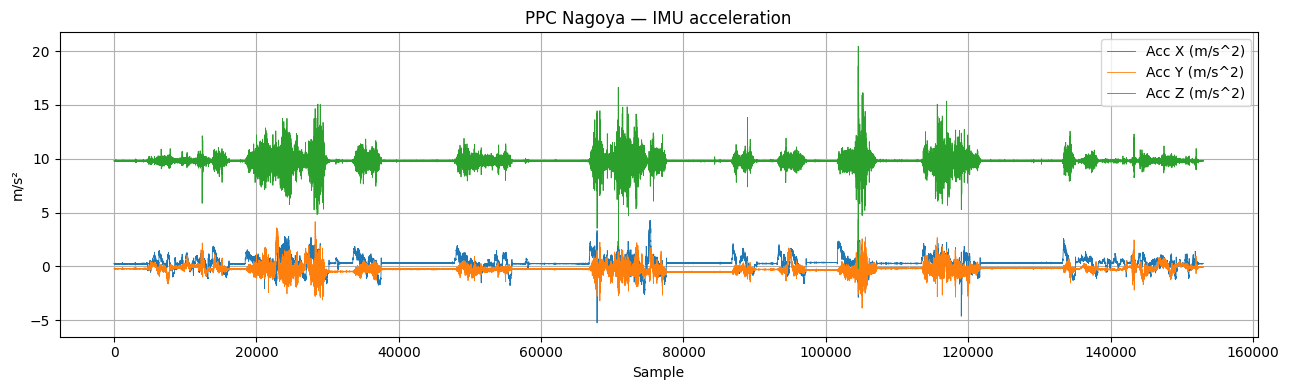

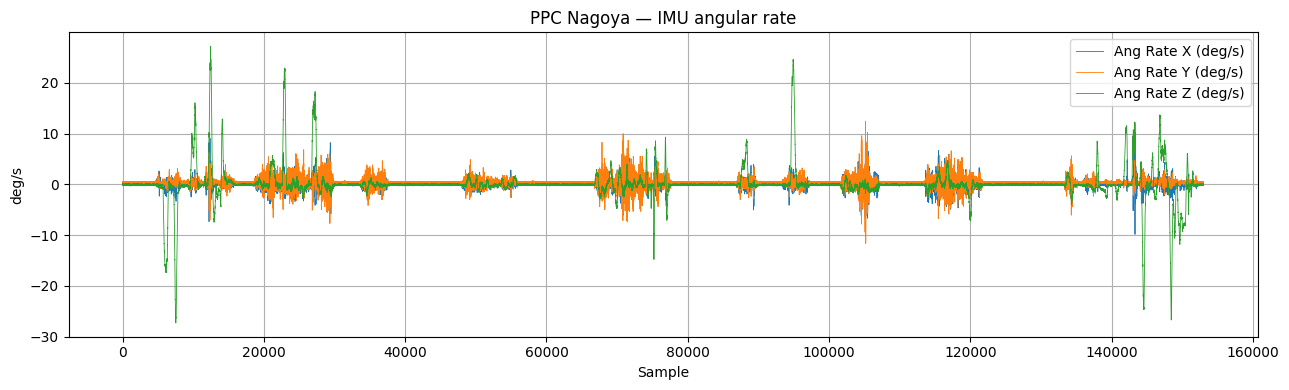


RINEX:
{
  "rover.obs": {
    "file": "rover.obs",
    "header_valid": true,
    "version": "3.04",
    "observation_types": {
      "G": [
        "C1C",
        "L1C",
        "D1C",
        "S1C",
        "C1W",
        "S1W",
        "C2W",
        "L2W",
        "D2W",
        "S2W",
        "C2L",
        "L2L",
        "D2L"
      ],
      " ": [
        "S2L",
        "C5Q",
        "L5Q",
        "D5Q",
        "S5Q",
        "L8Q",
        "D8Q",
        "S8Q",
        "L3Q",
        "D3Q",
        "S3Q",
        "L7I",
        "D7I",
        "S7I",
        "C6I",
        "L6I",
        "D6I",
        "S6I"
      ],
      "E": [
        "C1C",
        "L1C",
        "D1C",
        "S1C",
        "C5Q",
        "L5Q",
        "D5Q",
        "S5Q",
        "C7Q",
        "L7Q",
        "D7Q",
        "S7Q",
        "C8Q"
      ],
      "R": [
        "C1C",
        "L1C",
        "D1C",
        "S1C",
        "C2P",
        "L2P",
        "D2P",
        "S2P",
        "C2C",
 

In [33]:


# ================================================================
# ARQTECH LABS | VYRA
# PPC NAGOYA — SEMANTIC / PHYSICAL PROFILE
# READ ONLY — NO TRAINING — NO REPOSITORY CHANGES
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import re
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path("/content/vyra_ppc_validation/semantic_audit")
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 68)
print("VYRA | PPC SEMANTIC AUDIT")
print("=" * 68)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

imu.columns = [str(c).strip() for c in imu.columns]
ref.columns = [str(c).strip() for c in ref.columns]

def axis_profile(df, columns):
    result = {}
    for col in columns:
        if col not in df.columns:
            result[col] = {"status": "MISSING"}
            continue

        x = pd.to_numeric(df[col], errors="coerce").to_numpy()
        valid = x[np.isfinite(x)]

        result[col] = {
            "count": int(len(valid)),
            "invalid": int(len(x) - len(valid)),
            "mean": float(np.mean(valid)),
            "std": float(np.std(valid)),
            "min": float(np.min(valid)),
            "max": float(np.max(valid)),
            "p01": float(np.quantile(valid, 0.01)),
            "p50": float(np.quantile(valid, 0.50)),
            "p99": float(np.quantile(valid, 0.99))
        }
    return result

acc_cols = [
    "Acc X (m/s^2)",
    "Acc Y (m/s^2)",
    "Acc Z (m/s^2)"
]

gyro_cols = [
    "Ang Rate X (deg/s)",
    "Ang Rate Y (deg/s)",
    "Ang Rate Z (deg/s)"
]

acc = imu[acc_cols].apply(pd.to_numeric, errors="coerce").to_numpy()
gyro = imu[gyro_cols].apply(pd.to_numeric, errors="coerce").to_numpy()

acc_norm = np.linalg.norm(acc, axis=1)
gyro_norm = np.linalg.norm(gyro, axis=1)

# WGS84 geodetic -> ECEF, used only for consistency diagnostic.
def geodetic_to_ecef(lat_deg, lon_deg, height):
    a = 6378137.0
    f = 1 / 298.257223563
    e2 = f * (2 - f)

    lat = np.deg2rad(lat_deg)
    lon = np.deg2rad(lon_deg)

    N = a / np.sqrt(1 - e2 * np.sin(lat)**2)

    x = (N + height) * np.cos(lat) * np.cos(lon)
    y = (N + height) * np.cos(lat) * np.sin(lon)
    z = (N * (1-e2) + height) * np.sin(lat)

    return np.column_stack([x, y, z])

coordinate_cols = [
    "Latitude (deg)",
    "Longitude (deg)",
    "Ellipsoid Height (m)",
    "ECEF X (m)",
    "ECEF Y (m)",
    "ECEF Z (m)"
]

coordinate_check = {"status": "NOT_AVAILABLE"}

if all(c in ref.columns for c in coordinate_cols):
    lat = ref["Latitude (deg)"].to_numpy(float)
    lon = ref["Longitude (deg)"].to_numpy(float)
    h = ref["Ellipsoid Height (m)"].to_numpy(float)

    ecef_source = ref[
        ["ECEF X (m)", "ECEF Y (m)", "ECEF Z (m)"]
    ].to_numpy(float)

    ecef_calc = geodetic_to_ecef(lat, lon, h)
    residual = np.linalg.norm(ecef_calc - ecef_source, axis=1)

    coordinate_check = {
        "method": "WGS84 geodetic to ECEF",
        "median_difference_m": float(np.median(residual)),
        "p95_difference_m": float(np.quantile(residual, 0.95)),
        "max_difference_m": float(np.max(residual)),
        "finite": bool(np.all(np.isfinite(residual)))
    }

# Basic RINEX 3 inspection, no parser installation.
def inspect_rinex(path):
    result = {
        "file": path.name,
        "header_valid": False,
        "version": None,
        "observation_types": {},
        "epochs": 0,
        "first_epoch": None,
        "last_epoch": None
    }

    with path.open("r", errors="replace") as f:
        header = True

        for line in f:
            if header:
                if "RINEX VERSION / TYPE" in line:
                    result["version"] = line[:9].strip()

                if "SYS / # / OBS TYPES" in line:
                    system = line[0]
                    types = line[7:60].split()
                    result["observation_types"].setdefault(
                        system, []
                    ).extend(types)

                if "END OF HEADER" in line:
                    header = False
                    result["header_valid"] = True
                continue

            if line.startswith(">"):
                result["epochs"] += 1
                if result["first_epoch"] is None:
                    result["first_epoch"] = line.strip()
                result["last_epoch"] = line.strip()

    return result

rinex = {}
for name in ["rover.obs", "base.obs", "base.nav"]:
    path = ROOT / name
    if path.exists():
        rinex[name] = inspect_rinex(path)

# Reference attitude and velocity profiles.
ref_columns = [
    "Roll (deg)", "Pitch (deg)", "Heading (deg)",
    "East Velocity (m/s)",
    "North Velocity (m/s)",
    "Up Velocity (m/s)"
]

reference_profile = axis_profile(ref, ref_columns)

report = {
    "dataset": "PPC Nagoya Run 1",
    "imu_rows": len(imu),
    "reference_rows": len(ref),
    "imu_acceleration": axis_profile(imu, acc_cols),
    "imu_angular_rate": axis_profile(imu, gyro_cols),
    "acceleration_norm_median": float(np.nanmedian(acc_norm)),
    "acceleration_norm_p95": float(np.nanquantile(acc_norm, 0.95)),
    "angular_rate_norm_median_deg_s": float(np.nanmedian(gyro_norm)),
    "angular_rate_norm_p95_deg_s": float(np.nanquantile(gyro_norm, 0.95)),
    "reference_profile": reference_profile,
    "ecef_consistency": coordinate_check,
    "rinex": rinex,
    "limitations": [
        "No IMU calibration performed.",
        "No gravity compensation performed.",
        "No lever-arm correction performed.",
        "No GNSS solution computed.",
        "No sensor fusion performed.",
        "ECEF comparison is a coordinate consistency diagnostic only."
    ]
}

report_path = OUT / "semantic_physical_report.json"
report_path.write_text(json.dumps(report, indent=2))

# IMU plots
fig, ax = plt.subplots(figsize=(13, 4))
for i, col in enumerate(acc_cols):
    ax.plot(imu.index, acc[:, i], label=col, linewidth=0.6)
ax.set_title("PPC Nagoya — IMU acceleration")
ax.set_xlabel("Sample")
ax.set_ylabel("m/s²")
ax.legend()
ax.grid(True)
fig.tight_layout()
fig.savefig(OUT / "imu_acceleration.png", dpi=140)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(13, 4))
for i, col in enumerate(gyro_cols):
    ax.plot(imu.index, gyro[:, i], label=col, linewidth=0.6)
ax.set_title("PPC Nagoya — IMU angular rate")
ax.set_xlabel("Sample")
ax.set_ylabel("deg/s")
ax.legend()
ax.grid(True)
fig.tight_layout()
fig.savefig(OUT / "imu_angular_rate.png", dpi=140)
plt.show()
plt.close(fig)

print("\nRINEX:")
print(json.dumps(rinex, indent=2))

print("\nECEF CONSISTENCY:")
print(json.dumps(coordinate_check, indent=2))

print("\nREPORT:")
print(report_path)

print("\nAUDIT COMPLETE — NO SOURCE DATA MODIFIED")

ARQTECH LABS | VYRA — IMU QUALITY AUDIT


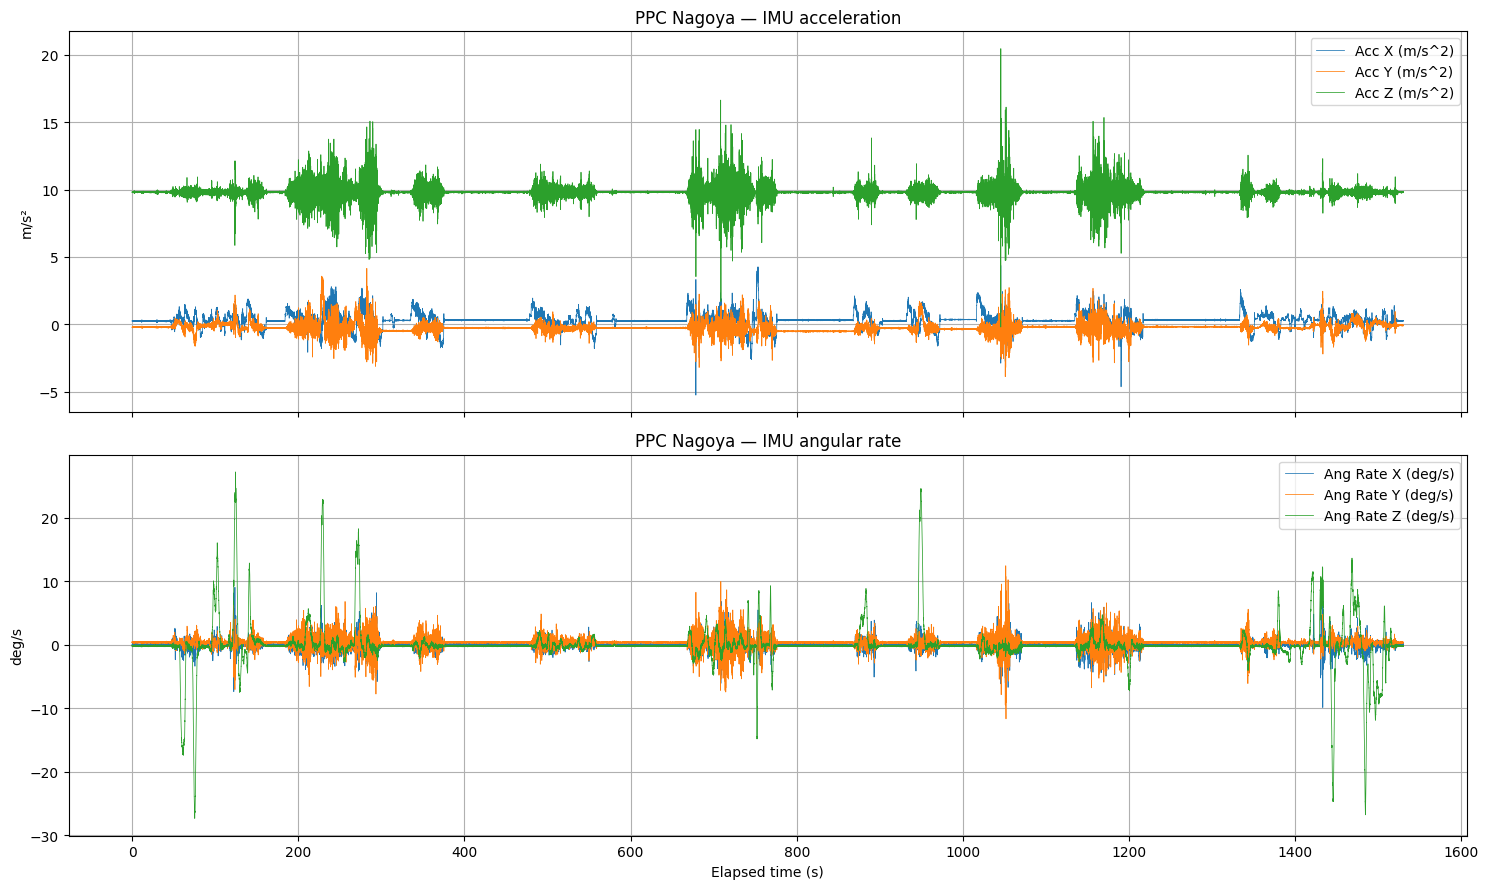

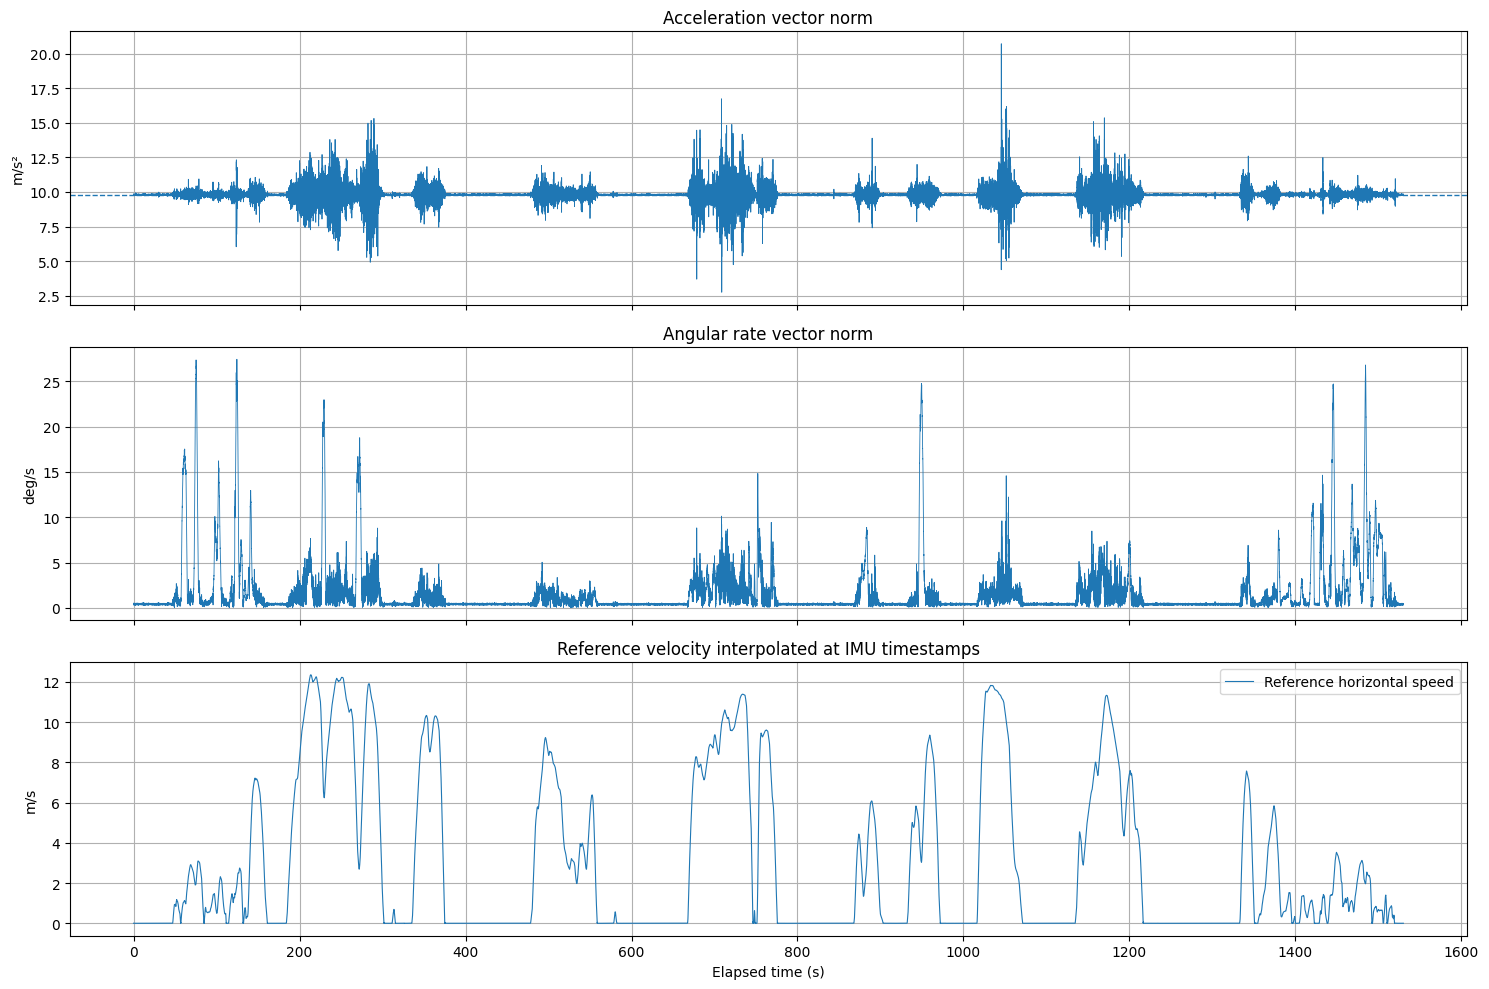


VYRA | IMU QUALITY AUDIT — SUMMARY

TEMPORAL:
{
  "rows": 153001,
  "valid_complete_rows": 153001,
  "invalid_rows": 0,
  "strictly_increasing": true,
  "duplicate_or_nonpositive_intervals": 0,
  "interval_median_s": 0.010000000009313226,
  "interval_min_s": 0.009999999892897904,
  "interval_max_s": 0.010000000009313226,
  "frequency_median_hz": 99.99999990686774,
  "duration_s": 1530.0
}

VECTOR NORMS:
{
  "acceleration_norm_m_s2": {
    "count": 153001,
    "mean": 9.822754674881521,
    "std": 0.40321064759589015,
    "min": 2.7495702564105358,
    "max": 20.71392546876165,
    "p0_1": 7.065261651669827,
    "p1": 8.561275346302821,
    "median": 9.810031689462386,
    "p99": 11.151689694688368,
    "p99_9": 12.683501212619683
  },
  "angular_rate_norm_deg_s": {
    "count": 153001,
    "mean": 1.68231618587059,
    "std": 3.118969971498209,
    "min": 0.021578345627040085,
    "max": 27.420682260385135,
    "p0_1": 0.12193748398257198,
    "p1": 0.23751644679895326,
    "median": 

In [34]:


# =====================================================================
# ARQTECH LABS | VYRA
# PPC NAGOYA RUN 1 — IMU QUALITY AUDIT
# READ ONLY | NO TRAINING | NO GIT CHANGES
# =====================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path("/content/vyra_ppc_validation/imu_quality_audit")
OUT.mkdir(parents=True, exist_ok=True)

IMU_FILE = ROOT / "imu.csv"
REF_FILE = ROOT / "reference.csv"

assert IMU_FILE.is_file(), f"IMU não encontrado: {IMU_FILE}"
assert REF_FILE.is_file(), f"Referência não encontrada: {REF_FILE}"

print("=" * 72)
print("ARQTECH LABS | VYRA — IMU QUALITY AUDIT")
print("=" * 72)

# ---------------------------------------------------------------------
# 1. LEITURA E NORMALIZAÇÃO DOS NOMES
# ---------------------------------------------------------------------

imu = pd.read_csv(IMU_FILE)
ref = pd.read_csv(REF_FILE)

imu.columns = [str(c).strip() for c in imu.columns]
ref.columns = [str(c).strip() for c in ref.columns]

acc_cols = [
    "Acc X (m/s^2)",
    "Acc Y (m/s^2)",
    "Acc Z (m/s^2)"
]

gyro_cols = [
    "Ang Rate X (deg/s)",
    "Ang Rate Y (deg/s)",
    "Ang Rate Z (deg/s)"
]

time_col = "GPS TOW (s)"

required_imu = [time_col] + acc_cols + gyro_cols
required_ref = [
    time_col,
    "East Velocity (m/s)",
    "North Velocity (m/s)",
    "Up Velocity (m/s)",
    "Heading (deg)"
]

for col in required_imu:
    assert col in imu.columns, f"Coluna IMU ausente: {col}"

for col in required_ref:
    assert col in ref.columns, f"Coluna referência ausente: {col}"

# Converter somente as colunas utilizadas.
for col in required_imu:
    imu[col] = pd.to_numeric(imu[col], errors="coerce")

for col in required_ref:
    ref[col] = pd.to_numeric(ref[col], errors="coerce")

# ---------------------------------------------------------------------
# 2. INTEGRIDADE E TEMPORALIDADE
# ---------------------------------------------------------------------

t = imu[time_col].to_numpy(dtype=float)
tr = ref[time_col].to_numpy(dtype=float)

imu_values = imu[acc_cols + gyro_cols].to_numpy(dtype=float)

finite_rows = (
    np.isfinite(t) &
    np.all(np.isfinite(imu_values), axis=1)
)

dt = np.diff(t)
positive_dt = dt[np.isfinite(dt) & (dt > 0)]

temporal = {
    "rows": int(len(imu)),
    "valid_complete_rows": int(finite_rows.sum()),
    "invalid_rows": int((~finite_rows).sum()),
    "strictly_increasing": bool(np.all(dt > 0)),
    "duplicate_or_nonpositive_intervals": int(np.sum(dt <= 0)),
    "interval_median_s": float(np.median(positive_dt)),
    "interval_min_s": float(np.min(positive_dt)),
    "interval_max_s": float(np.max(positive_dt)),
    "frequency_median_hz": float(1 / np.median(positive_dt)),
    "duration_s": float(t[-1] - t[0])
}

# ---------------------------------------------------------------------
# 3. PERFIL ESTATÍSTICO E VALORES EXTREMOS
# ---------------------------------------------------------------------

def describe_signal(values):
    values = np.asarray(values, dtype=float)
    valid = values[np.isfinite(values)]

    if len(valid) == 0:
        return {"status": "NO_VALID_VALUES"}

    q = np.quantile(valid, [0.001, 0.01, 0.50, 0.99, 0.999])

    return {
        "count": int(len(valid)),
        "mean": float(np.mean(valid)),
        "std": float(np.std(valid)),
        "min": float(np.min(valid)),
        "max": float(np.max(valid)),
        "p0_1": float(q[0]),
        "p1": float(q[1]),
        "median": float(q[2]),
        "p99": float(q[3]),
        "p99_9": float(q[4])
    }

signals = {}

for col in acc_cols + gyro_cols:
    signals[col] = describe_signal(imu[col].to_numpy())

# ---------------------------------------------------------------------
# 4. NORMAS DOS VETORES
# ---------------------------------------------------------------------

acc = imu[acc_cols].to_numpy(dtype=float)
gyro = imu[gyro_cols].to_numpy(dtype=float)

acc_norm = np.linalg.norm(acc, axis=1)
gyro_norm = np.linalg.norm(gyro, axis=1)

norms = {
    "acceleration_norm_m_s2": describe_signal(acc_norm),
    "angular_rate_norm_deg_s": describe_signal(gyro_norm)
}

# ---------------------------------------------------------------------
# 5. DETECÇÃO ROBUSTA DE PICOS CANDIDATOS
# ---------------------------------------------------------------------
# Rolling median + MAD.
# Estes pontos são candidatos estatísticos, não falhas confirmadas.

def robust_spike_audit(series, window=501, threshold=8.0):
    s = pd.Series(series, dtype=float)

    rolling_median = s.rolling(
        window=window,
        center=True,
        min_periods=max(25, window // 4)
    ).median()

    deviation = (s - rolling_median).abs()

    rolling_mad = deviation.rolling(
        window=window,
        center=True,
        min_periods=max(25, window // 4)
    ).median()

    robust_sigma = 1.4826 * rolling_mad
    score = deviation / robust_sigma.replace(0, np.nan)

    # Quando MAD é zero, não inferimos spike automaticamente.
    mask = score > threshold

    return {
        "candidate_count": int(mask.sum()),
        "candidate_fraction": float(mask.mean()),
        "threshold_robust_sigma": threshold,
        "window_samples": window,
        "candidate_indices": np.flatnonzero(
            mask.fillna(False).to_numpy()
        )[:100].tolist()
    }

spikes = {}

for col in acc_cols + gyro_cols:
    spikes[col] = robust_spike_audit(
        imu[col].to_numpy()
    )

# ---------------------------------------------------------------------
# 6. REPETIÇÕES CONSECUTIVAS E PLATEAUS
# ---------------------------------------------------------------------

def repeated_value_audit(values):
    x = np.asarray(values, dtype=float)
    valid = np.isfinite(x)

    same = (
        valid[1:] &
        valid[:-1] &
        (x[1:] == x[:-1])
    )

    longest = 0
    current = 0

    for is_same in same:
        if is_same:
            current += 1
            longest = max(longest, current + 1)
        else:
            current = 0

    return {
        "equal_adjacent_pairs": int(same.sum()),
        "equal_pair_fraction": float(same.mean()),
        "longest_identical_run_samples": int(longest)
    }

repetition = {
    col: repeated_value_audit(imu[col].to_numpy())
    for col in acc_cols + gyro_cols
}

# ---------------------------------------------------------------------
# 7. CANDIDATOS A CLIPPING — NÃO CONFIRMAR SATURAÇÃO
# ---------------------------------------------------------------------
# Verifica concentração exata nos extremos observados.
# Sem datasheet/configuração do sensor, não prova clipping.

extreme_values = {}

for col in acc_cols + gyro_cols:
    x = imu[col].to_numpy(dtype=float)
    x = x[np.isfinite(x)]

    vmin = np.min(x)
    vmax = np.max(x)

    extreme_values[col] = {
        "observed_min": float(vmin),
        "count_at_observed_min": int(np.sum(x == vmin)),
        "observed_max": float(vmax),
        "count_at_observed_max": int(np.sum(x == vmax)),
        "interpretation": "observed extrema only; clipping unconfirmed"
    }

# ---------------------------------------------------------------------
# 8. COERÊNCIA TEMPORAL COM A REFERÊNCIA
# ---------------------------------------------------------------------

ref_valid = (
    np.isfinite(tr) &
    np.isfinite(ref["East Velocity (m/s)"].to_numpy()) &
    np.isfinite(ref["North Velocity (m/s)"].to_numpy()) &
    np.isfinite(ref["Up Velocity (m/s)"].to_numpy())
)

ref_clean = ref.loc[ref_valid].copy()

ref_t = ref_clean[time_col].to_numpy(dtype=float)

assert len(ref_t) >= 2
assert np.all(np.diff(ref_t) > 0), (
    "Timestamps da referência não são estritamente crescentes."
)

# Velocidade da referência interpolada nos instantes IMU.
# Isto é apenas alinhamento temporal, não integração de sensores.

east = np.interp(
    t, ref_t,
    ref_clean["East Velocity (m/s)"].to_numpy()
)

north = np.interp(
    t, ref_t,
    ref_clean["North Velocity (m/s)"].to_numpy()
)

up = np.interp(
    t, ref_t,
    ref_clean["Up Velocity (m/s)"].to_numpy()
)

reference_speed_3d = np.sqrt(east**2 + north**2 + up**2)
reference_speed_horizontal = np.sqrt(east**2 + north**2)

reference_alignment = {
    "imu_start_tow_s": float(t[0]),
    "imu_end_tow_s": float(t[-1]),
    "reference_start_tow_s": float(ref_t[0]),
    "reference_end_tow_s": float(ref_t[-1]),
    "imu_samples_inside_reference_interval": int(
        np.sum((t >= ref_t[0]) & (t <= ref_t[-1]))
    ),
    "reference_horizontal_speed_median": float(
        np.median(reference_speed_horizontal)
    ),
    "reference_horizontal_speed_p95": float(
        np.quantile(reference_speed_horizontal, 0.95)
    ),
    "reference_3d_speed_median": float(
        np.median(reference_speed_3d)
    )
}

# ---------------------------------------------------------------------
# 9. JANELAS DE BAIXA DINÂMICA — APENAS CANDIDATAS
# ---------------------------------------------------------------------
# Heurística exploratória: norma da aceleração próxima de g
# e baixa norma angular. Não equivale a detectar repouso verdadeiro.

low_dynamic = (
    np.isfinite(acc_norm) &
    np.isfinite(gyro_norm) &
    (np.abs(acc_norm - 9.80665) < 0.35) &
    (gyro_norm < 1.0)
)

low_dynamic_report = {
    "candidate_samples": int(low_dynamic.sum()),
    "candidate_fraction": float(low_dynamic.mean()),
    "candidate_duration_approx_s": float(
        low_dynamic.sum() * np.median(positive_dt)
    ),
    "warning": (
        "Heuristic only. Requires frame/orientation and calibration "
        "validation before being called stationary."
    )
}

# ---------------------------------------------------------------------
# 10. GRÁFICOS
# ---------------------------------------------------------------------

# Aceleração e giroscópio em tempo real aproximado.
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

for i, col in enumerate(acc_cols):
    axes[0].plot(t - t[0], acc[:, i], label=col, linewidth=0.55)

axes[0].set_title("PPC Nagoya — IMU acceleration")
axes[0].set_ylabel("m/s²")
axes[0].legend()
axes[0].grid(True)

for i, col in enumerate(gyro_cols):
    axes[1].plot(t - t[0], gyro[:, i], label=col, linewidth=0.55)

axes[1].set_title("PPC Nagoya — IMU angular rate")
axes[1].set_xlabel("Elapsed time (s)")
axes[1].set_ylabel("deg/s")
axes[1].legend()
axes[1].grid(True)

fig.tight_layout()
fig.savefig(OUT / "01_imu_signals_vs_time.png", dpi=150)
plt.show()
plt.close(fig)

# Normas e velocidade de referência.
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

axes[0].plot(t - t[0], acc_norm, linewidth=0.6)
axes[0].axhline(9.80665, linestyle="--", linewidth=1)
axes[0].set_title("Acceleration vector norm")
axes[0].set_ylabel("m/s²")
axes[0].grid(True)

axes[1].plot(t - t[0], gyro_norm, linewidth=0.6)
axes[1].set_title("Angular rate vector norm")
axes[1].set_ylabel("deg/s")
axes[1].grid(True)

axes[2].plot(
    t - t[0],
    reference_speed_horizontal,
    label="Reference horizontal speed",
    linewidth=0.8
)
axes[2].set_title("Reference velocity interpolated at IMU timestamps")
axes[2].set_ylabel("m/s")
axes[2].set_xlabel("Elapsed time (s)")
axes[2].legend()
axes[2].grid(True)

fig.tight_layout()
fig.savefig(OUT / "02_norms_and_reference_speed.png", dpi=150)
plt.show()
plt.close(fig)

# ---------------------------------------------------------------------
# 11. RELATÓRIO
# ---------------------------------------------------------------------

def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

report = {
    "project": "VYRA",
    "dataset": "PPC Nagoya Run 1",
    "audit": "IMU Quality Audit",
    "read_only": True,
    "source_files": {
        "imu_csv_sha256": sha256_file(IMU_FILE),
        "reference_csv_sha256": sha256_file(REF_FILE)
    },
    "temporal_integrity": temporal,
    "signal_statistics": signals,
    "vector_norms": norms,
    "robust_spike_candidates": spikes,
    "repeated_values": repetition,
    "observed_extrema": extreme_values,
    "reference_alignment": reference_alignment,
    "low_dynamic_candidates": low_dynamic_report,
    "limitations": [
        "No sensor datasheet full-scale limits were applied.",
        "No clipping or saturation was confirmed.",
        "No IMU calibration was performed.",
        "No gravity compensation was performed.",
        "No lever-arm correction was performed.",
        "No sensor fusion or state estimation was performed.",
        "Reference velocity was interpolated only for time alignment.",
        "Low-dynamic windows are heuristic candidates only."
    ]
}

report_path = OUT / "imu_quality_report.json"
report_path.write_text(json.dumps(report, indent=2))

# CSV de amostras candidatas para inspeção.
candidate_rows = []

for col, result in spikes.items():
    for idx in result["candidate_indices"]:
        candidate_rows.append({
            "signal": col,
            "sample_index": idx,
            "gps_tow_s": float(t[idx]),
            "value": float(imu.iloc[idx][col])
        })

pd.DataFrame(candidate_rows).to_csv(
    OUT / "spike_candidates.csv",
    index=False
)

print("\n" + "=" * 72)
print("VYRA | IMU QUALITY AUDIT — SUMMARY")
print("=" * 72)

print("\nTEMPORAL:")
print(json.dumps(temporal, indent=2))

print("\nVECTOR NORMS:")
print(json.dumps(norms, indent=2))

print("\nREFERENCE ALIGNMENT:")
print(json.dumps(reference_alignment, indent=2))

print("\nLOW-DYNAMIC CANDIDATES:")
print(json.dumps(low_dynamic_report, indent=2))

print("\nSPIKE CANDIDATES:")
for col, result in spikes.items():
    print(
        f"{col}: {result['candidate_count']} "
        f"({result['candidate_fraction']:.4%})"
    )

print("\nOUTPUTS:")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"{p.name} | {p.stat().st_size / 1024:.1f} KB")

print("\nREPORT:", report_path)
print("SOURCE DATA MODIFIED: NO")
print("TRAINING EXECUTED: NO")
print("GITHUB MODIFIED: NO")
print("=" * 72)

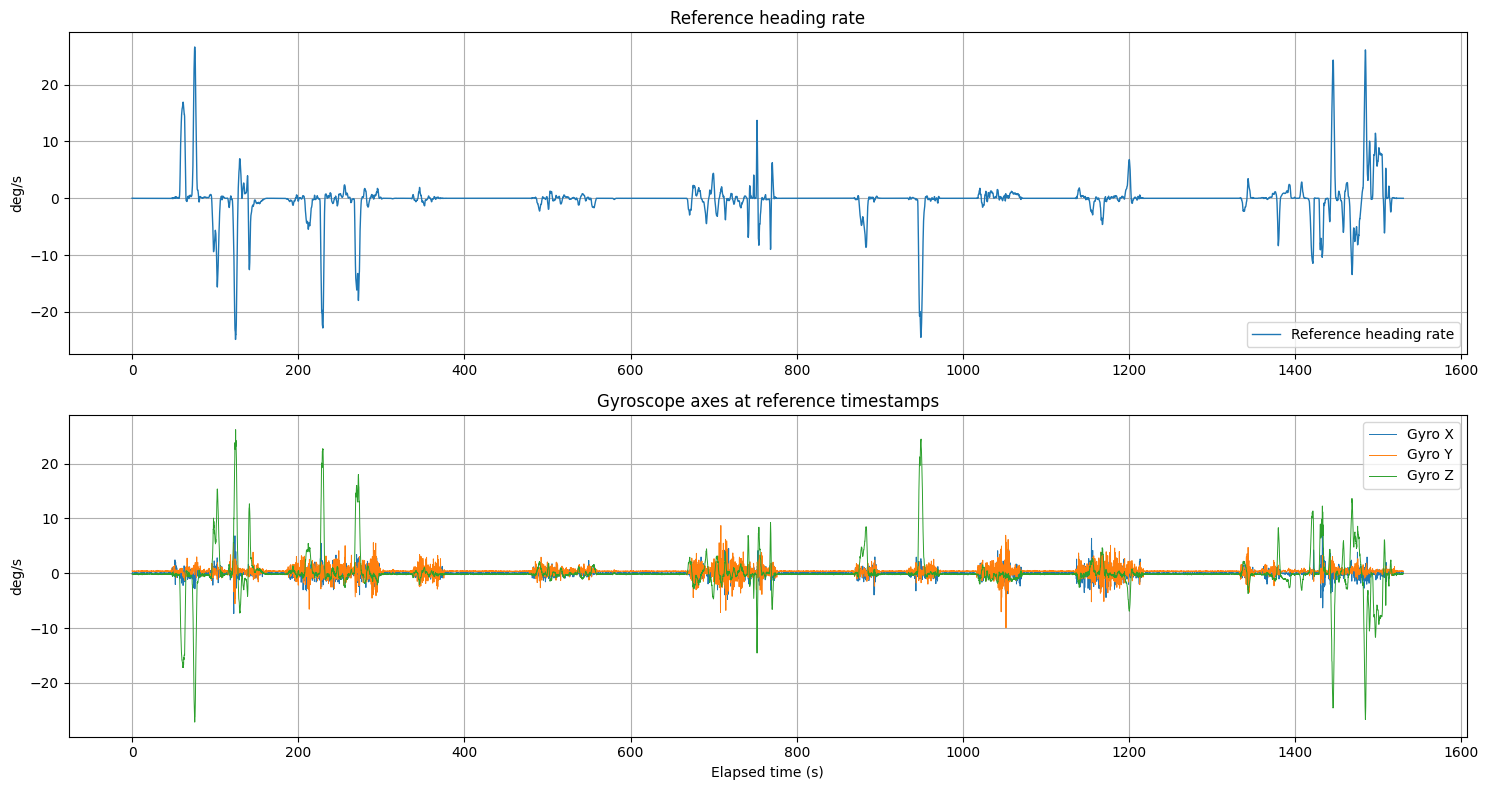

VYRA | AXIS CORRELATION AUDIT

HEADING RATE:
{
  "reference_samples": 7651,
  "heading_rate_mean_deg_s": -0.17504280486234558,
  "heading_rate_std_deg_s": 3.343046495377927,
  "heading_rate_p95_abs_deg_s": 6.837499999664612,
  "heading_rate_max_abs_deg_s": 26.624999998333795
}

BEST CORRELATION PER AXIS:
axis  lag_samples  lag_seconds  correlation
   X            5          1.0    -0.158298
   Y            0          0.0     0.066447
   Z            0          0.0    -0.999164

OUTPUT: /content/vyra_ppc_validation/axis_correlation_audit
SOURCE MODIFIED: NO
GITHUB MODIFIED: NO


In [35]:


# ================================================================
# VYRA | PPC NAGOYA
# IMU ↔ REFERENCE ROTATION CORRELATION
# READ ONLY
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path("/content/vyra_ppc_validation/axis_correlation_audit")
OUT.mkdir(parents=True, exist_ok=True)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

imu.columns = imu.columns.str.strip()
ref.columns = ref.columns.str.strip()

t = imu["GPS TOW (s)"].to_numpy(float)
tr = ref["GPS TOW (s)"].to_numpy(float)

gyro_cols = [
    "Ang Rate X (deg/s)",
    "Ang Rate Y (deg/s)",
    "Ang Rate Z (deg/s)"
]

gyro = imu[gyro_cols].to_numpy(float)

heading = np.unwrap(
    np.deg2rad(ref["Heading (deg)"].to_numpy(float))
)

# Derivada angular em rad/s convertida para deg/s.
heading_rate = np.rad2deg(
    np.gradient(heading, tr)
)

# Giroscópio interpolado nos instantes da referência.
gyro_ref = np.column_stack([
    np.interp(tr, t, gyro[:, i])
    for i in range(3)
])

# Correlação com lags de -1 a +1 segundo.
# 5 Hz: cada amostra equivale aproximadamente a 0,2 s.
max_lag_samples = 5

results = []

for axis_idx, axis_name in enumerate(["X", "Y", "Z"]):
    x = gyro_ref[:, axis_idx]

    for lag in range(-max_lag_samples, max_lag_samples + 1):
        if lag < 0:
            a = x[-lag:]
            b = heading_rate[:len(heading_rate) + lag]
        elif lag > 0:
            a = x[:-lag]
            b = heading_rate[lag:]
        else:
            a = x
            b = heading_rate

        valid = np.isfinite(a) & np.isfinite(b)
        a, b = a[valid], b[valid]

        if len(a) < 10 or np.std(a) == 0 or np.std(b) == 0:
            corr = None
        else:
            corr = float(np.corrcoef(a, b)[0, 1])

        results.append({
            "axis": axis_name,
            "lag_samples": lag,
            "lag_seconds": lag * 0.2,
            "correlation": corr
        })

results_df = pd.DataFrame(results)

# Melhor correlação absoluta por eixo.
best = []

for axis in ["X", "Y", "Z"]:
    subset = results_df[
        (results_df["axis"] == axis) &
        results_df["correlation"].notna()
    ].copy()

    if len(subset):
        row = subset.loc[
            subset["correlation"].abs().idxmax()
        ]
        best.append(row.to_dict())

best_df = pd.DataFrame(best)

# Estatísticas gerais de heading.
heading_report = {
    "reference_samples": int(len(ref)),
    "heading_rate_mean_deg_s": float(np.mean(heading_rate)),
    "heading_rate_std_deg_s": float(np.std(heading_rate)),
    "heading_rate_p95_abs_deg_s": float(
        np.quantile(np.abs(heading_rate), 0.95)
    ),
    "heading_rate_max_abs_deg_s": float(
        np.max(np.abs(heading_rate))
    )
}

# Salvar resultados.
results_df.to_csv(
    OUT / "all_axis_lag_correlations.csv",
    index=False
)

best_df.to_csv(
    OUT / "best_axis_correlations.csv",
    index=False
)

report = {
    "dataset": "PPC Nagoya Run 1",
    "method": "Pearson correlation between gyro axes and reference heading rate",
    "heading_rate": heading_report,
    "best_correlations": best,
    "limitations": [
        "Correlation does not establish physical axis alignment.",
        "Heading convention and sign are not independently confirmed.",
        "Reference heading derivative is sampled at 5 Hz.",
        "No IMU calibration or mounting rotation was applied.",
        "No sensor fusion or state estimation was performed."
    ]
}

(OUT / "axis_correlation_report.json").write_text(
    json.dumps(report, indent=2)
)

# Plot comparison.
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(
    tr - tr[0],
    heading_rate,
    label="Reference heading rate",
    linewidth=1
)
axes[0].set_title("Reference heading rate")
axes[0].set_ylabel("deg/s")
axes[0].grid(True)
axes[0].legend()

for i, axis in enumerate(["X", "Y", "Z"]):
    axes[1].plot(
        tr - tr[0],
        gyro_ref[:, i],
        label=f"Gyro {axis}",
        linewidth=0.7
    )

axes[1].set_title("Gyroscope axes at reference timestamps")
axes[1].set_xlabel("Elapsed time (s)")
axes[1].set_ylabel("deg/s")
axes[1].grid(True)
axes[1].legend()

fig.tight_layout()
fig.savefig(
    OUT / "heading_rate_vs_gyro.png",
    dpi=150
)
plt.show()
plt.close(fig)

print("=" * 68)
print("VYRA | AXIS CORRELATION AUDIT")
print("=" * 68)

print("\nHEADING RATE:")
print(json.dumps(heading_report, indent=2))

print("\nBEST CORRELATION PER AXIS:")
print(best_df.to_string(index=False))

print("\nOUTPUT:", OUT)
print("SOURCE MODIFIED: NO")
print("GITHUB MODIFIED: NO")

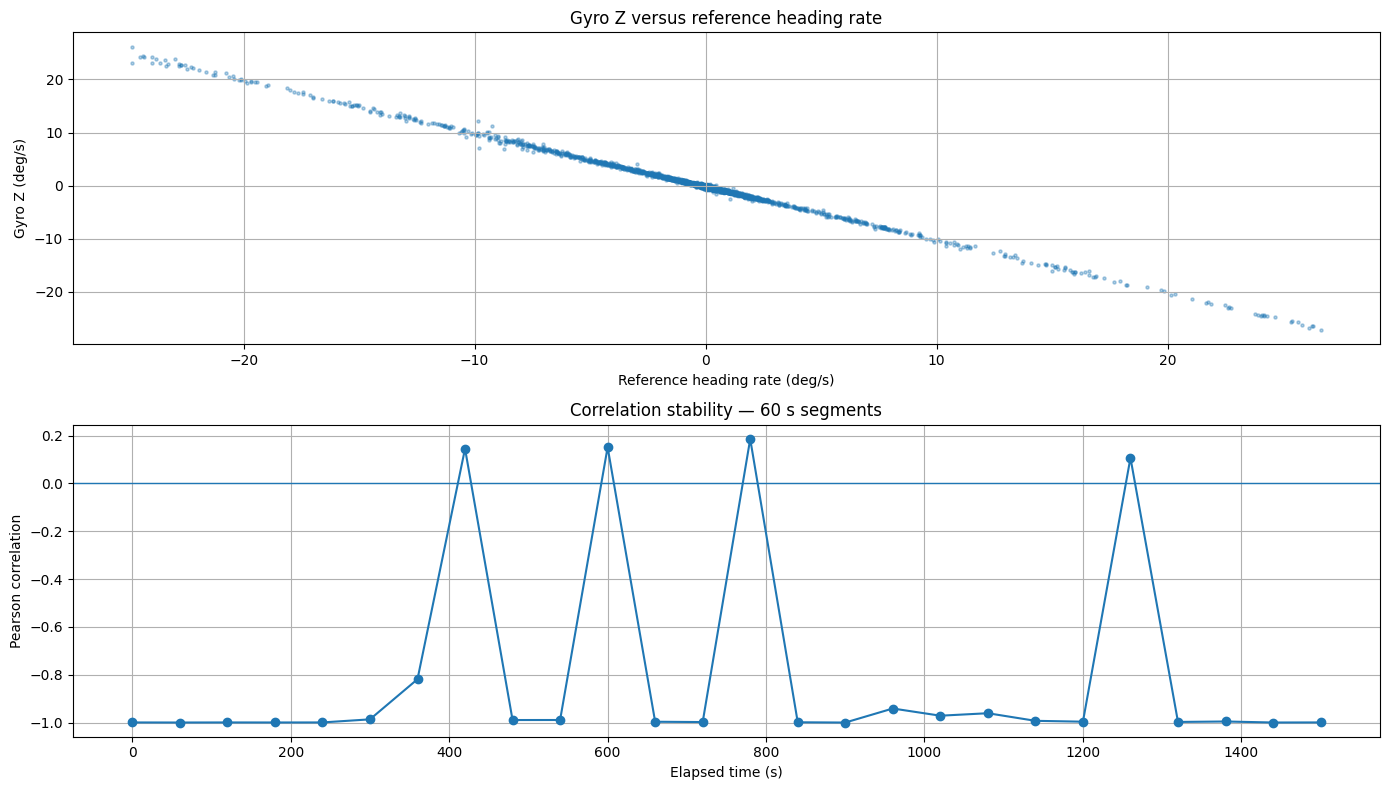

VYRA | GYRO Z CONSISTENCY

FULL SEQUENCE:
{
  "n": 7651,
  "correlation": -0.9991635990363027,
  "slope_gyroZ_per_heading_rate": -1.0025660024152294,
  "intercept_deg_s": -0.16278496603730438,
  "rmse_deg_s": 0.1371671820226689,
  "mae_deg_s": 0.08064949920675428,
  "residual_p95_abs_deg_s": 0.2598579094491208
}

ANGULAR DYNAMIC SUBSET:
{
  "n": 2016,
  "correlation": -0.9994246702449839,
  "slope_gyroZ_per_heading_rate": -1.002597192667708,
  "intercept_deg_s": -0.16313506879490108,
  "rmse_deg_s": 0.22050168647944132,
  "mae_deg_s": 0.13920673317240662,
  "residual_p95_abs_deg_s": 0.379752613387073
}

BEST LAG:
{
  "lag_s": 8.881784197001252e-16,
  "correlation": -0.9991635990363027,
  "absolute_correlation": 0.9991635990363027
}

SEGMENTS:
 start_elapsed_s  end_elapsed_s   n  correlation  slope_gyroZ_per_heading_rate  intercept_deg_s  rmse_deg_s  mae_deg_s  residual_p95_abs_deg_s
             0.0           60.0 300    -0.999391                     -1.001846        -0.161510    0.074

In [36]:


# ================================================================
# ARQTECH LABS | VYRA
# PPC — GYRO Z / HEADING CONSISTENCY VALIDATION
# READ ONLY | NO TRAINING | NO GITHUB CHANGES
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path(
    "/content/vyra_ppc_validation/gyro_z_consistency"
)
OUT.mkdir(parents=True, exist_ok=True)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

imu.columns = imu.columns.str.strip()
ref.columns = ref.columns.str.strip()

t = imu["GPS TOW (s)"].to_numpy(float)
tr = ref["GPS TOW (s)"].to_numpy(float)

gyro_z = imu["Ang Rate Z (deg/s)"].to_numpy(float)

# Heading em radianos, desembrulhado para evitar saltos em +/-180°.
heading = np.unwrap(
    np.deg2rad(ref["Heading (deg)"].to_numpy(float))
)

heading_rate = np.rad2deg(
    np.gradient(heading, tr)
)

# Interpolação do gyro nos timestamps da referência.
gyro_z_ref = np.interp(tr, t, gyro_z)

def metrics(x, y):
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]

    if len(x) < 10 or np.std(x) == 0 or np.std(y) == 0:
        return {"n": int(len(x)), "correlation": None}

    slope, intercept = np.polyfit(x, y, 1)
    predicted = slope * x + intercept
    residual = y - predicted

    return {
        "n": int(len(x)),
        "correlation": float(np.corrcoef(x, y)[0, 1]),
        "slope_gyroZ_per_heading_rate": float(slope),
        "intercept_deg_s": float(intercept),
        "rmse_deg_s": float(np.sqrt(np.mean(residual**2))),
        "mae_deg_s": float(np.mean(np.abs(residual))),
        "residual_p95_abs_deg_s": float(
            np.quantile(np.abs(residual), 0.95)
        )
    }

# Teste geral e somente nos períodos de dinâmica angular.
full = metrics(heading_rate, gyro_z_ref)

dynamic_mask = np.abs(heading_rate) >= 0.5
dynamic = metrics(
    heading_rate[dynamic_mask],
    gyro_z_ref[dynamic_mask]
)

# Correlação por segmentos de 60 segundos.
segment_results = []
segment_duration = 60.0

for start in np.arange(
    tr[0], tr[-1], segment_duration
):
    mask = (
        (tr >= start) &
        (tr < start + segment_duration)
    )

    if mask.sum() < 20:
        continue

    result = metrics(
        heading_rate[mask],
        gyro_z_ref[mask]
    )

    segment_results.append({
        "start_elapsed_s": float(start - tr[0]),
        "end_elapsed_s": float(
            min(start + segment_duration, tr[-1]) - tr[0]
        ),
        **result
    })

# Busca de atraso usando deslocamentos de 20 ms.
# Convenção: lag positivo amostra o gyro em instante posterior.
lag_results = []

for lag in np.arange(-1.0, 1.0001, 0.02):
    shifted = np.interp(
        tr + lag,
        t,
        gyro_z,
        left=np.nan,
        right=np.nan
    )

    valid = (
        np.isfinite(shifted) &
        np.isfinite(heading_rate)
    )

    if valid.sum() < 20:
        continue

    corr = np.corrcoef(
        heading_rate[valid],
        shifted[valid]
    )[0, 1]

    lag_results.append({
        "lag_s": float(lag),
        "correlation": float(corr),
        "absolute_correlation": float(abs(corr))
    })

lag_df = pd.DataFrame(lag_results)
best_lag = lag_df.loc[
    lag_df["absolute_correlation"].idxmax()
].to_dict()

segments_df = pd.DataFrame(segment_results)

# Relatório
report = {
    "dataset": "PPC Nagoya Run 1",
    "comparison": "reference heading rate vs interpolated IMU gyro Z",
    "full_sequence": full,
    "angular_dynamic_subset_abs_heading_rate_ge_0_5_deg_s": dynamic,
    "best_lag": best_lag,
    "lag_search_range_s": [-1.0, 1.0],
    "lag_step_s": 0.02,
    "segment_duration_s": segment_duration,
    "segments": segment_results,
    "limitations": [
        "Correlation does not prove physical sensor-axis alignment.",
        "No mounting rotation or calibration was applied.",
        "Heading convention must be confirmed.",
        "Reference heading derivative is sampled at approximately 5 Hz.",
        "Linear fit is diagnostic, not a calibration result."
    ]
}

(OUT / "gyro_z_consistency_report.json").write_text(
    json.dumps(report, indent=2)
)

segments_df.to_csv(
    OUT / "segment_correlations.csv",
    index=False
)

lag_df.to_csv(
    OUT / "lag_sweep.csv",
    index=False
)

# Gráficos
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].scatter(
    heading_rate,
    gyro_z_ref,
    s=5,
    alpha=0.35
)
axes[0].set_xlabel("Reference heading rate (deg/s)")
axes[0].set_ylabel("Gyro Z (deg/s)")
axes[0].set_title("Gyro Z versus reference heading rate")
axes[0].grid(True)

axes[1].plot(
    segments_df["start_elapsed_s"],
    segments_df["correlation"],
    marker="o"
)
axes[1].axhline(0, linewidth=1)
axes[1].set_xlabel("Elapsed time (s)")
axes[1].set_ylabel("Pearson correlation")
axes[1].set_title("Correlation stability — 60 s segments")
axes[1].grid(True)

fig.tight_layout()
fig.savefig(OUT / "gyro_z_consistency.png", dpi=160)
plt.show()
plt.close(fig)

print("=" * 68)
print("VYRA | GYRO Z CONSISTENCY")
print("=" * 68)
print("\nFULL SEQUENCE:")
print(json.dumps(full, indent=2))
print("\nANGULAR DYNAMIC SUBSET:")
print(json.dumps(dynamic, indent=2))
print("\nBEST LAG:")
print(json.dumps(best_lag, indent=2))
print("\nSEGMENTS:")
print(segments_df.to_string(index=False))
print("\nOUTPUT:", OUT)
print("SOURCE DATA MODIFIED: NO")
print("TRAINING: NOT EXECUTED")
print("GITHUB: NOT MODIFIED")

In [37]:


# ================================================================
# VYRA | PPC — TEMPORAL HOLDOUT VALIDATION
# Gyro Z vs Reference Heading Rate
# READ ONLY
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path(
    "/content/vyra_ppc_validation/gyro_z_holdout"
)
OUT.mkdir(parents=True, exist_ok=True)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

imu.columns = imu.columns.str.strip()
ref.columns = ref.columns.str.strip()

t = imu["GPS TOW (s)"].to_numpy(float)
tr = ref["GPS TOW (s)"].to_numpy(float)

gyro_z = imu["Ang Rate Z (deg/s)"].to_numpy(float)

heading = np.unwrap(
    np.deg2rad(ref["Heading (deg)"].to_numpy(float))
)

heading_rate = np.rad2deg(np.gradient(heading, tr))
gyro_ref = np.interp(tr, t, gyro_z)

# Máscara de movimento angular informativo.
valid = (
    np.isfinite(heading_rate) &
    np.isfinite(gyro_ref) &
    (np.abs(heading_rate) >= 0.5)
)

# Divisão cronológica: primeiros 70% para ajuste.
split = int(len(tr) * 0.70)

train = valid & (np.arange(len(tr)) < split)
test = valid & (np.arange(len(tr)) >= split)

if train.sum() < 100 or test.sum() < 100:
    raise RuntimeError("Amostras insuficientes para validação.")

# Modelo: gyro_z = slope * heading_rate + intercept
slope, intercept = np.polyfit(
    heading_rate[train],
    gyro_ref[train],
    1
)

def evaluate(mask):
    x = heading_rate[mask]
    y = gyro_ref[mask]
    pred = slope * x + intercept
    residual = y - pred

    return {
        "n": int(mask.sum()),
        "correlation": float(np.corrcoef(x, y)[0, 1]),
        "rmse_deg_s": float(np.sqrt(np.mean(residual**2))),
        "mae_deg_s": float(np.mean(np.abs(residual))),
        "residual_p95_abs_deg_s": float(
            np.quantile(np.abs(residual), 0.95)
        ),
        "bias_residual_deg_s": float(np.mean(residual))
    }

train_result = evaluate(train)
test_result = evaluate(test)

# Avaliação por janelas no período de teste.
window_results = []

test_start = tr[split]
test_end = tr[-1]
window_seconds = 60.0

for start in np.arange(
    test_start, test_end, window_seconds
):
    mask = (
        test &
        (tr >= start) &
        (tr < start + window_seconds)
    )

    if mask.sum() < 20:
        continue

    x = heading_rate[mask]
    y = gyro_ref[mask]
    pred = slope * x + intercept
    residual = y - pred

    window_results.append({
        "elapsed_start_s": float(start - tr[0]),
        "samples": int(mask.sum()),
        "correlation": float(np.corrcoef(x, y)[0, 1]),
        "rmse_deg_s": float(np.sqrt(np.mean(residual**2))),
        "mae_deg_s": float(np.mean(np.abs(residual)))
    })

report = {
    "dataset": "PPC Nagoya Run 1",
    "split": "chronological 70% train / 30% test",
    "dynamic_threshold_abs_heading_rate_deg_s": 0.5,
    "model": {
        "formula": "gyro_z = slope * heading_rate + intercept",
        "slope": float(slope),
        "intercept_deg_s": float(intercept)
    },
    "train": train_result,
    "test": test_result,
    "test_windows": window_results,
    "limitations": [
        "Empirical relationship, not certified sensor calibration.",
        "Reference heading convention remains to be confirmed.",
        "No physical mounting rotation was applied.",
        "Temporal holdout is not an independent dataset.",
        "No sensor fusion or training was performed."
    ]
}

(OUT / "holdout_validation_report.json").write_text(
    json.dumps(report, indent=2)
)

pd.DataFrame(window_results).to_csv(
    OUT / "test_window_metrics.csv",
    index=False
)

print("=" * 68)
print("VYRA | TEMPORAL HOLDOUT VALIDATION")
print("=" * 68)
print("\nMODEL:")
print(json.dumps(report["model"], indent=2))
print("\nTRAIN:")
print(json.dumps(train_result, indent=2))
print("\nTEST — UNSEEN TIME PERIOD:")
print(json.dumps(test_result, indent=2))
print("\nTEST WINDOWS:")
print(pd.DataFrame(window_results).to_string(index=False))
print("\nREPORT:", OUT / "holdout_validation_report.json")
print("SOURCE DATA MODIFIED: NO")
print("GITHUB MODIFIED: NO")
print("TRAINING: NOT EXECUTED")

VYRA | TEMPORAL HOLDOUT VALIDATION

MODEL:
{
  "formula": "gyro_z = slope * heading_rate + intercept",
  "slope": -1.002452527118269,
  "intercept_deg_s": -0.16581515750021644
}

TRAIN:
{
  "n": 1341,
  "correlation": -0.9995717786584504,
  "rmse_deg_s": 0.188676744604764,
  "mae_deg_s": 0.12952121460973906,
  "residual_p95_abs_deg_s": 0.34485404564422595,
  "bias_residual_deg_s": 4.983998962150218e-17
}

TEST — UNSEEN TIME PERIOD:
{
  "n": 675,
  "correlation": -0.9990907884101741,
  "rmse_deg_s": 0.2729784470910979,
  "mae_deg_s": 0.15855386015598996,
  "residual_p95_abs_deg_s": 0.4545365733420754,
  "bias_residual_deg_s": 0.008302864646516979
}

TEST WINDOWS:
 elapsed_start_s  samples  correlation  rmse_deg_s  mae_deg_s
          1131.0       85    -0.993248    0.209428   0.166011
          1191.0       45    -0.999121    0.104905   0.089887
          1311.0       48    -0.998464    0.104999   0.080628
          1371.0      159    -0.999440    0.138793   0.083361
          1431.0   